# NeuroEmo fMRI — Digital Image Processing Capstone

## Emotion Recognition from Functional MRI

This notebook implements Digital Image Processing techniques on
4D fMRI data from the NeuroEmo dataset, followed by feature
extraction and emotion recognition.

### Dataset
- 40 subjects
- 5 emotional states
- Task: emotion elicitation (`task-fe`)
- fMRI data stored as NIfTI (`.nii.gz`)

In [23]:
import os
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path

print("Imports successful!")

Imports successful!


In [24]:
from pathlib import Path

# Project and dataset paths
PROJECT_DIR = Path(r"D:\coding\coding\projects\PROJECTS\Dip_capstone")
CODE_DIR = PROJECT_DIR / "code"
DATA_DIR = CODE_DIR / "data"

print("Project directory:")
print(PROJECT_DIR)

print("\nDataset directory:")
print(DATA_DIR)

print("\nDataset exists:", DATA_DIR.exists())

Project directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone

Dataset directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data

Dataset exists: True


In [25]:
subjects = sorted(
    [p for p in DATA_DIR.glob("sub-*") if p.is_dir()]
)

print("Number of subjects:", len(subjects))

print("\nSubjects:")
for subject in subjects:
    print(subject.name)

Number of subjects: 40

Subjects:
sub-01
sub-02
sub-03
sub-04
sub-05
sub-06
sub-07
sub-08
sub-09
sub-10
sub-11
sub-12
sub-13
sub-14
sub-15
sub-16
sub-17
sub-18
sub-19
sub-20
sub-21
sub-22
sub-23
sub-24
sub-25
sub-26
sub-27
sub-28
sub-29
sub-30
sub-31
sub-32
sub-33
sub-34
sub-35
sub-36
sub-37
sub-38
sub-39
sub-40


In [26]:
structure_check = []

for subject in subjects:
    structure_check.append({
        "Subject": subject.name,
        "Anat": (subject / "anat").exists(),
        "Func": (subject / "func").exists()
    })

structure_df = pd.DataFrame(structure_check)

structure_df

,Subject,Anat,Func
0,sub-01,True,True
1,sub-02,True,True
2,sub-03,True,True
3,sub-04,True,True
4,sub-05,True,True
5,sub-06,True,True
6,sub-07,True,True
7,sub-08,True,True
8,sub-09,True,True
9,sub-10,True,True


In [27]:
fmri_files = []

for subject in subjects:
    func_dir = subject / "func"

    files = list(func_dir.glob("*_task-fe_bold.nii.gz"))

    fmri_files.append({
        "Subject": subject.name,
        "Task_fMRI_File": files[0].name if files else None,
        "Exists": len(files) > 0,
        "Size_MB": round(files[0].stat().st_size / (1024**2), 2)
                    if files else 0
    })

fmri_df = pd.DataFrame(fmri_files)

fmri_df

,Subject,Task_fMRI_File,Exists,Size_MB
0,sub-01,sub-01_task-fe_bold.nii.gz,True,97.57
1,sub-02,sub-02_task-fe_bold.nii.gz,True,98.39
2,sub-03,sub-03_task-fe_bold.nii.gz,True,93.97
3,sub-04,sub-04_task-fe_bold.nii.gz,True,97.62
4,sub-05,sub-05_task-fe_bold.nii.gz,True,97.00
5,sub-06,sub-06_task-fe_bold.nii.gz,True,96.85
6,sub-07,sub-07_task-fe_bold.nii.gz,True,104.15
7,sub-08,sub-08_task-fe_bold.nii.gz,True,101.63
8,sub-09,sub-09_task-fe_bold.nii.gz,True,91.41
9,sub-10,sub-10_task-fe_bold.nii.gz,True,103.35


In [28]:
print(
    "Task-fMRI files found:",
    fmri_df["Exists"].sum(),
    "/",
    len(fmri_df)
)

Task-fMRI files found: 40 / 40


In [29]:
dataset_info = []

for subject in subjects:

    fmri_path = (
        subject
        / "func"
        / f"{subject.name}_task-fe_bold.nii.gz"
    )

    img = nib.load(fmri_path)

    dataset_info.append({
        "Subject": subject.name,
        "Shape": img.shape,
        "Voxel_X": img.header.get_zooms()[0],
        "Voxel_Y": img.header.get_zooms()[1],
        "Voxel_Z": img.header.get_zooms()[2],
        "TR": img.header.get_zooms()[3]
    })

dataset_info_df = pd.DataFrame(dataset_info)

dataset_info_df

,Subject,Shape,Voxel_X,Voxel_Y,Voxel_Z,TR
0,sub-01,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
1,sub-02,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
2,sub-03,"(128, 128, 36, 200)",1.789827,1.789827,4.0,3.000001
3,sub-04,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
4,sub-05,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
5,sub-06,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
6,sub-07,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
7,sub-08,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
8,sub-09,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
9,sub-10,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001


In [30]:
# Load one subject's complete 4D fMRI dataset

subject_id = "sub-01"

fmri_path = (
    DATA_DIR
    / subject_id
    / "func"
    / f"{subject_id}_task-fe_bold.nii.gz"
)

print("Loading:", fmri_path)

fmri_img = nib.load(fmri_path)

print("Shape:", fmri_img.shape)
print("Data type:", fmri_img.get_data_dtype())
print("Voxel size:", fmri_img.header.get_zooms()[:3])
print("TR:", fmri_img.header.get_zooms()[3])

Loading: D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-01\func\sub-01_task-fe_bold.nii.gz
Shape: (128, 128, 36, 200)
Data type: int16
Voxel size: (1.796875, 1.796875, 4.0)
TR: 3.000001


In [31]:
fmri_data = fmri_img.get_fdata()

print("Data shape:", fmri_data.shape)
print("Data type:", fmri_data.dtype)
print("Minimum intensity:", fmri_data.min())
print("Maximum intensity:", fmri_data.max())
print("Mean intensity:", fmri_data.mean())
print("Standard deviation:", fmri_data.std())

volume_0 = fmri_data[:, :, :, 0]

print("3D volume shape:", volume_0.shape)

Data shape: (128, 128, 36, 200)
Data type: float64
Minimum intensity: 0.0
Maximum intensity: 132305.96348190308
Mean intensity: 7060.439963178646
Standard deviation: 15352.282345290087
3D volume shape: (128, 128, 36)


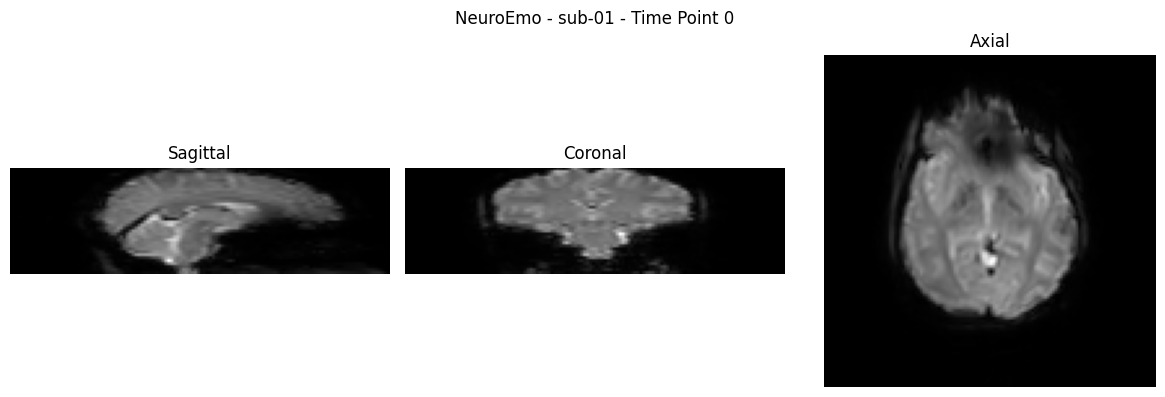

In [32]:
x = volume_0.shape[0] // 2
y = volume_0.shape[1] // 2
z = volume_0.shape[2] // 2

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(volume_0[x, :, :].T, cmap="gray", origin="lower")
plt.title("Sagittal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(volume_0[:, y, :].T, cmap="gray", origin="lower")
plt.title("Coronal")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(volume_0[:, :, z].T, cmap="gray", origin="lower")
plt.title("Axial")
plt.axis("off")

plt.suptitle("NeuroEmo - sub-01 - Time Point 0")
plt.tight_layout()
plt.show()

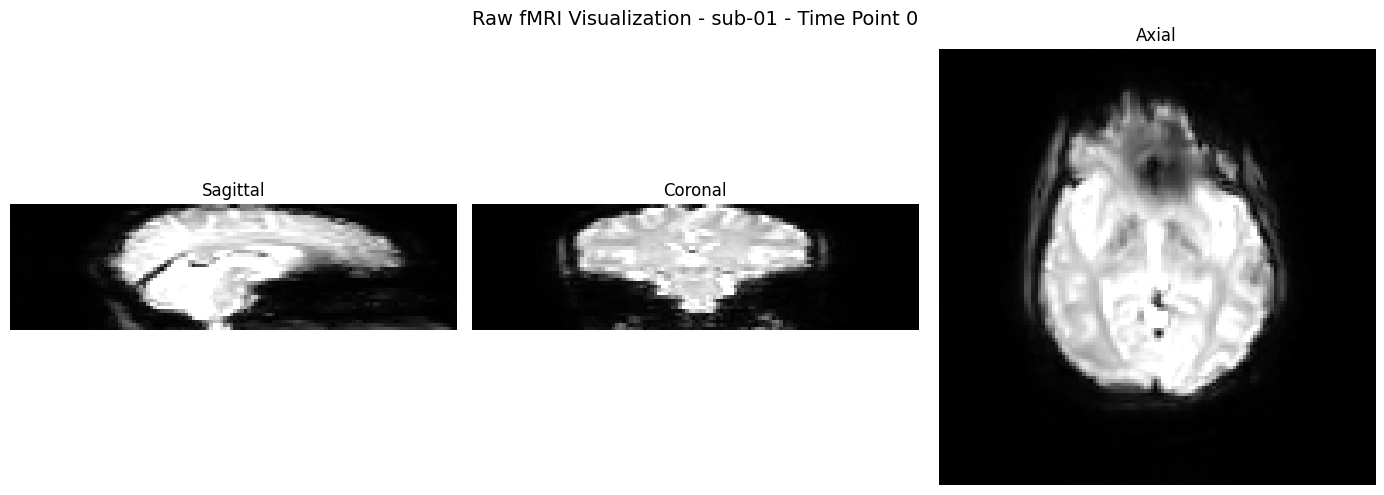

Display intensity range:
2nd percentile : 0.0
98th percentile: 53216.63787460327


In [33]:
# Display the middle slices with percentile-based intensity normalization

vmin = np.percentile(volume_0, 2)
vmax = np.percentile(volume_0, 98)

x = volume_0.shape[0] // 2
y = volume_0.shape[1] // 2
z = volume_0.shape[2] // 2

plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    volume_0[x, :, :].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Sagittal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    volume_0[:, y, :].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Coronal")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    volume_0[:, :, z].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Axial")
plt.axis("off")

plt.suptitle(
    f"Raw fMRI Visualization - {subject_id} - Time Point 0",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Display intensity range:")
print("2nd percentile :", vmin)
print("98th percentile:", vmax)

In [13]:
# Histogram analysis - raw 4D fMRI

p1 = np.percentile(fmri_data, 1)
p25 = np.percentile(fmri_data, 25)
p50 = np.percentile(fmri_data, 50)
p75 = np.percentile(fmri_data, 75)
p99 = np.percentile(fmri_data, 99)

print("Raw fMRI Intensity Statistics")
print("-" * 40)
print(f"Minimum       : {fmri_data.min():.2f}")
print(f"1st percentile: {p1:.2f}")
print(f"25th percentile: {p25:.2f}")
print(f"Median        : {p50:.2f}")
print(f"75th percentile: {p75:.2f}")
print(f"99th percentile: {p99:.2f}")
print(f"Maximum       : {fmri_data.max():.2f}")
print(f"Mean          : {fmri_data.mean():.2f}")
print(f"Std deviation : {fmri_data.std():.2f}")

Raw fMRI Intensity Statistics
----------------------------------------
Minimum       : 0.00
1st percentile: 0.00
25th percentile: 35.88
Median        : 179.42
75th percentile: 2045.41
99th percentile: 56733.31
Maximum       : 132305.96
Mean          : 7060.44
Std deviation : 15352.28


In [14]:
zero_voxels = np.sum(fmri_data == 0)
total_voxels = fmri_data.size

zero_percentage = (zero_voxels / total_voxels) * 100

print("Background / Zero Intensity Analysis")
print("-" * 40)
print(f"Total voxels : {total_voxels:,}")
print(f"Zero voxels  : {zero_voxels:,}")
print(f"Zero percentage: {zero_percentage:.2f}%")

Background / Zero Intensity Analysis
----------------------------------------
Total voxels : 117,964,800
Zero voxels  : 11,266,923
Zero percentage: 9.55%


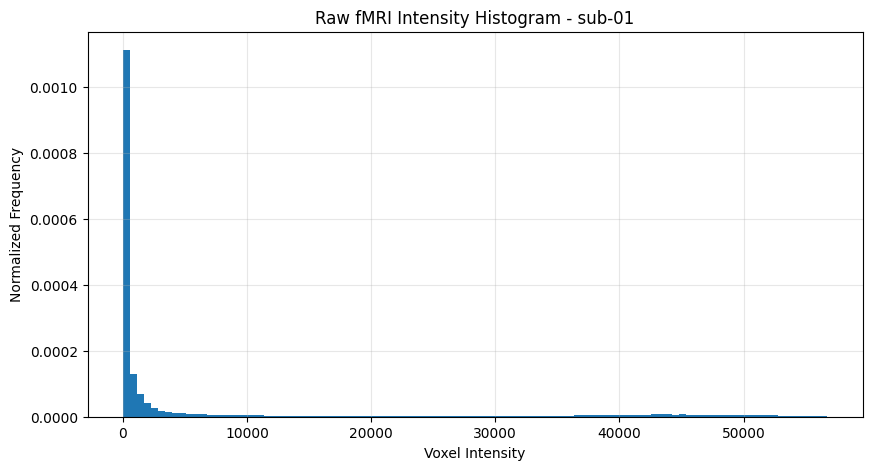

In [15]:
plt.figure(figsize=(10, 5))

display_max = np.percentile(fmri_data, 99)

plt.hist(
    fmri_data.flatten(),
    bins=100,
    range=(0, display_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Raw fMRI Intensity Histogram - sub-01")
plt.grid(alpha=0.3)

plt.show()

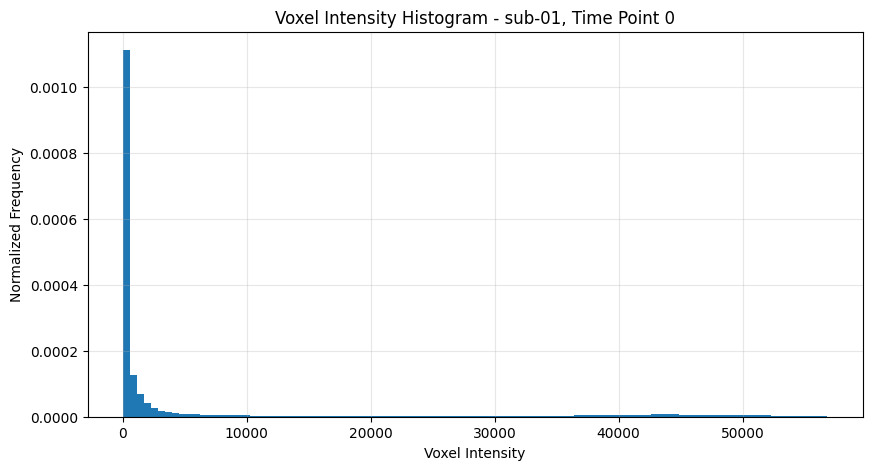

In [16]:
plt.figure(figsize=(10, 5))

volume_max = np.percentile(volume_0, 99)

plt.hist(
    volume_0.flatten(),
    bins=100,
    range=(0, volume_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Voxel Intensity Histogram - sub-01, Time Point 0")
plt.grid(alpha=0.3)

plt.show()

## Image Quantization

### Reference

**Reference:**  
Rafael C. Gonzalez and Richard E. Woods,  
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Image Sampling and Quantization.

### Concept

Quantization is the process of mapping a continuous or
high-resolution range of image intensity values to a finite
number of discrete intensity levels.

In this project, quantization is demonstrated on a 2D slice
of the NeuroEmo fMRI volume to study the effect of reducing
the number of available intensity levels.

### Application to NeuroEmo

The raw fMRI data contains a large range of voxel intensity
values. We experimentally reduce the number of intensity
levels and evaluate the resulting information loss using
visual comparison, MSE, and PSNR.

In [17]:
# ============================================================
# IMAGE QUANTIZATION
# Step 1: Prepare 2D fMRI slice
# ============================================================

# First 3D volume from the 4D fMRI dataset
volume_0 = fmri_data[:, :, :, 0]

# Select middle axial slice
z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape       :", fmri_data.shape)
print("3D volume shape     :", volume_0.shape)
print("2D slice shape      :", original_slice.shape)
print("Minimum intensity   :", original_slice.min())
print("Maximum intensity   :", original_slice.max())

4D fMRI shape       : (128, 128, 36, 200)
3D volume shape     : (128, 128, 36)
2D slice shape      : (128, 128)
Minimum intensity   : 0.0
Maximum intensity   : 97641.58574295044


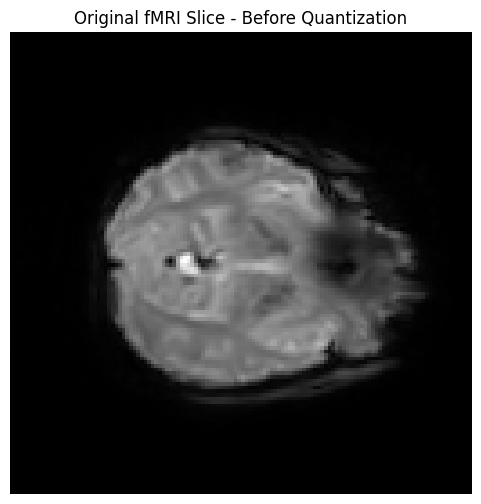

In [18]:
plt.figure(figsize=(6, 6))

plt.imshow(
    original_slice,
    cmap="gray",
    origin="lower"
)

plt.title("Original fMRI Slice - Before Quantization")
plt.axis("off")
plt.show()

## Quantization Function

The quantization process reduces the number of possible intensity
levels in an image.

For an image with intensity values in the range [I_min, I_max],
the intensity values are normalized and mapped to a finite number
of discrete levels.

In this experiment, the same fMRI slice will be quantized using:

- 256 intensity levels
- 64 intensity levels
- 16 intensity levels
- 4 intensity levels

This allows us to observe how reducing the number of intensity
levels affects image quality.

In [19]:
# ============================================================
# IMAGE QUANTIZATION
# Step 3: Define Quantization Function
# ============================================================

def quantize_image(image, levels):
    """
    Quantize an image into a specified number of intensity levels.
    """

    image_min = image.min()
    image_max = image.max()

    # Normalize intensity values to [0, 1]
    normalized = (
        (image - image_min) /
        (image_max - image_min)
    )

    # Map normalized values to discrete levels
    quantized = np.floor(
        normalized * (levels - 1)
    )

    # Reconstruct intensity values
    reconstructed = (
        quantized / (levels - 1)
    ) * (image_max - image_min) + image_min

    return reconstructed


print("Quantization function defined successfully.")

# Test the quantization function

test_quantized = quantize_image(
    original_slice,
    16
)

print("Original minimum :", original_slice.min())
print("Original maximum :", original_slice.max())

print("Quantized minimum:", test_quantized.min())
print("Quantized maximum:", test_quantized.max())

print(
    "Number of unique values:",
    len(np.unique(test_quantized))
)

Quantization function defined successfully.
Original minimum : 0.0
Original maximum : 97641.58574295044
Quantized minimum: 0.0
Quantized maximum: 97641.58574295044
Number of unique values: 16


In [20]:
# ============================================================
# IMAGE QUANTIZATION
# Step 4: Apply Different Quantization Levels
# ============================================================

quantized_256 = quantize_image(original_slice, 256)
quantized_64  = quantize_image(original_slice, 64)
quantized_16  = quantize_image(original_slice, 16)
quantized_4   = quantize_image(original_slice, 4)

print("Quantization completed successfully.")
print("Levels tested: 256, 64, 16, 4")


# Verify the number of unique intensity levels

quantized_images = {
    256: quantized_256,
    64: quantized_64,
    16: quantized_16,
    4: quantized_4
}

for levels, image in quantized_images.items():
    unique_values = np.unique(image)

    print(
        f"{levels:>3} levels → "
        f"{len(unique_values)} unique intensity values"
    )

Quantization completed successfully.
Levels tested: 256, 64, 16, 4
256 levels → 207 unique intensity values
 64 levels → 61 unique intensity values
 16 levels → 16 unique intensity values
  4 levels → 4 unique intensity values


## Visual Comparison of Quantization Levels

The original fMRI slice is compared with versions quantized to
256, 64, 16, and 4 intensity levels.

As the number of available intensity levels decreases, the image
contains fewer distinguishable gray levels. This can produce
visible intensity banding and loss of subtle image details.

The same display range is used for all images so that the visual
comparison is consistent.

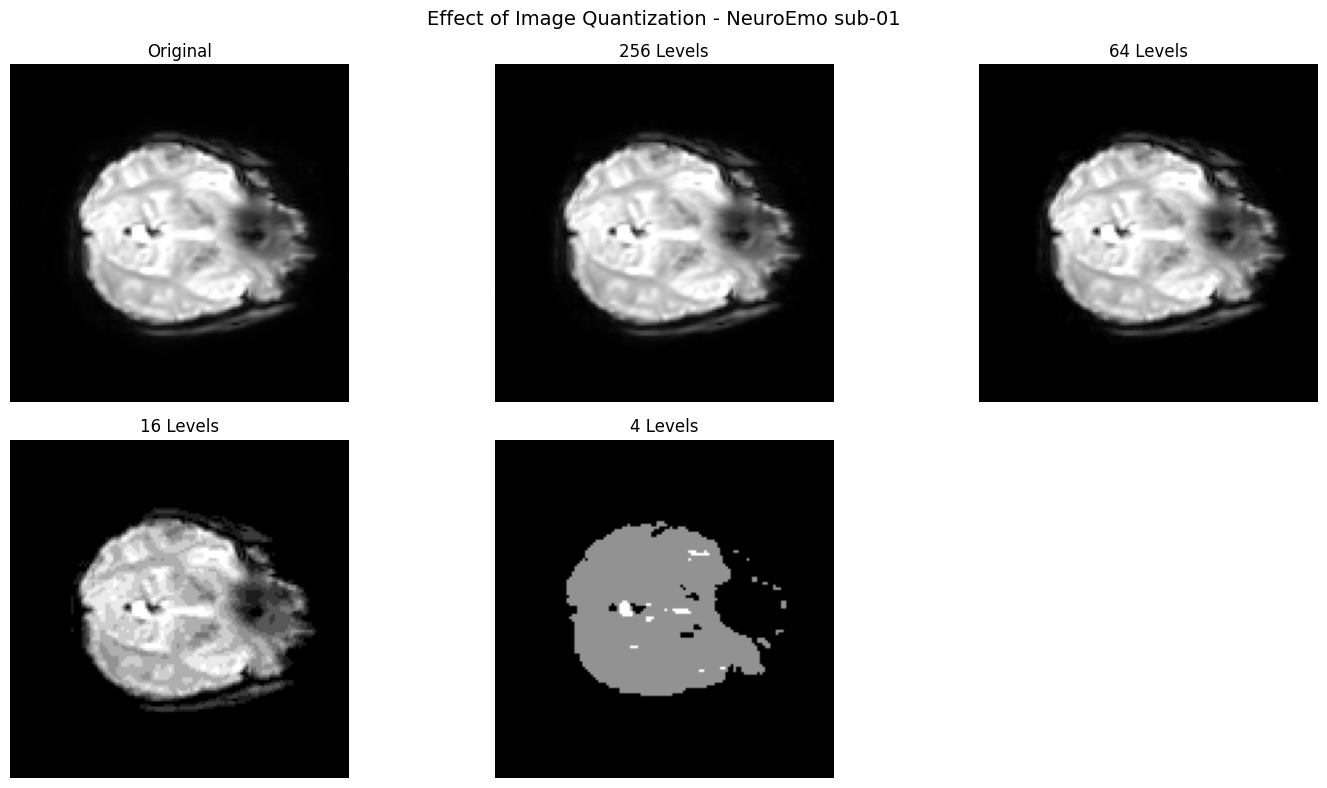

In [21]:
# ============================================================
# IMAGE QUANTIZATION
# Step 5: Visual Comparison
# ============================================================

vmin = np.percentile(original_slice, 2)
vmax = np.percentile(original_slice, 98)

images = [
    original_slice,
    quantized_256,
    quantized_64,
    quantized_16,
    quantized_4
]

titles = [
    "Original",
    "256 Levels",
    "64 Levels",
    "16 Levels",
    "4 Levels"
]

plt.figure(figsize=(15, 8))

for i, (image, title) in enumerate(
    zip(images, titles), 1
):

    plt.subplot(2, 3, i)

    plt.imshow(
        image,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    plt.title(title)
    plt.axis("off")

plt.suptitle(
    "Effect of Image Quantization - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Evaluation of Quantization

Visual inspection shows increasing intensity information loss as
the number of quantization levels decreases.

To quantify this degradation, Mean Squared Error (MSE) and
Peak Signal-to-Noise Ratio (PSNR) are calculated between the
original fMRI slice and each quantized version.

### Mean Squared Error

MSE measures the average squared difference between the original
and quantized images.

Lower MSE indicates less distortion.

### Peak Signal-to-Noise Ratio

PSNR expresses the reconstruction quality in decibels (dB).

Higher PSNR indicates lower distortion.

In [22]:
# ============================================================
# IMAGE QUANTIZATION
# Step 6: Quantitative Evaluation
# ============================================================

def calculate_metrics(original, processed):
    """
    Calculate MSE and PSNR between original and processed images.
    """

    # Mean Squared Error
    mse = np.mean(
        (original - processed) ** 2
    )

    # Dynamic range of original image
    data_range = (
        original.max() -
        original.min()
    )

    # Peak Signal-to-Noise Ratio
    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10(
            (data_range ** 2) / mse
        )

    return mse, psnr

quantization_results = []

for levels, image in quantized_images.items():

    mse, psnr = calculate_metrics(
        original_slice,
        image
    )

    quantization_results.append({
        "Quantization Levels": levels,
        "MSE": mse,
        "PSNR (dB)": psnr
    })

quantization_df = pd.DataFrame(
    quantization_results
)

quantization_df

,Quantization Levels,MSE,PSNR (dB)
0,256,3.188476e+04,54.756865
1,64,3.806451e+05,43.987494
2,16,5.078111e+06,32.735674
3,4,8.916046e+07,20.290974


## Quantization Analysis

The quantitative results demonstrate a clear relationship between
the number of intensity levels and image distortion.

When the number of quantization levels decreases from 256 to 4,
the MSE increases substantially from approximately 3.19 × 10^4
to 8.92 × 10^7.

At the same time, PSNR decreases from approximately 54.76 dB
to 20.29 dB.

Therefore, reducing the number of intensity levels introduces
increasing quantization error and reduces the fidelity of the
reconstructed image.

This observation agrees with the visual results, where the
4-level image shows significant intensity banding and loss of
subtle information compared with the original image.

# Intensity Transformations

## 1. Image Negative Transformation

### Reference

Gonzalez, R. C., & Woods, R. E.  
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Intensity Transformations.

### Concept

The image negative transformation reverses the intensity levels
of an image.

For an image with intensity range [0, L - 1], the negative
transformation is given by:

s = (L - 1) - r

where:

- r = input pixel intensity
- s = output pixel intensity
- L = number of possible intensity levels

For the continuous-valued fMRI image used in this project,
the minimum and maximum intensity values of the selected slice
are used as the intensity range.

The transformation is therefore:

s = I_max - r + I_min

### Objective

- Demonstrate image negative transformation on real fMRI data.
- Reverse the intensity values of the image.
- Compare the original and negative images.
- Analyze the effect of the transformation on image appearance
  and intensity distribution.

In [34]:
# ============================================================
# IMAGE NEGATIVE TRANSFORMATION
# Step 1: Prepare the original fMRI slice
# ============================================================

volume_0 = fmri_data[:, :, :, 0]

z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape     :", fmri_data.shape)
print("3D volume shape   :", volume_0.shape)
print("2D slice shape    :", original_slice.shape)
print("Minimum intensity :", original_slice.min())
print("Maximum intensity :", original_slice.max())

4D fMRI shape     : (128, 128, 36, 200)
3D volume shape   : (128, 128, 36)
2D slice shape    : (128, 128)
Minimum intensity : 0.0
Maximum intensity : 97641.58574295044


In [35]:
# ============================================================
# IMAGE NEGATIVE TRANSFORMATION
# Step 2: Apply Negative Transformation
# ============================================================

image_min = original_slice.min()
image_max = original_slice.max()

negative_image = (
    image_max - original_slice + image_min
)

print("Negative transformation completed.")
print("Original minimum :", image_min)
print("Original maximum :", image_max)

print("Negative minimum :", negative_image.min())
print("Negative maximum :", negative_image.max())

Negative transformation completed.
Original minimum : 0.0
Original maximum : 97641.58574295044
Negative minimum : 0.0
Negative maximum : 97641.58574295044


## Visual Comparison — Image Negative

The original fMRI slice is compared with its negative
transformation.

The negative transformation reverses the intensity ordering:
high-intensity regions become low-intensity regions and
low-intensity regions become high-intensity regions.

The same display intensity range is used for both images
to provide a consistent visual comparison.

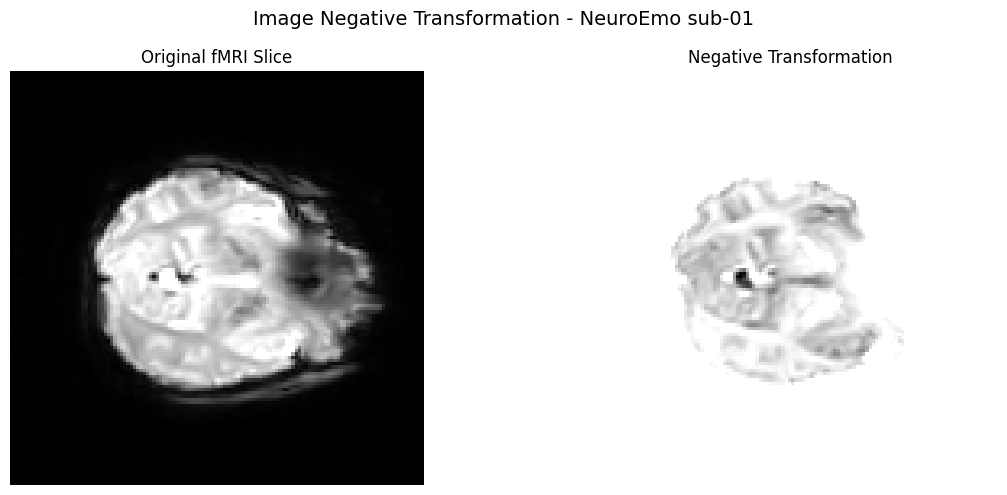

In [37]:
# ============================================================
# IMAGE NEGATIVE TRANSFORMATION
# Step 3: Visual Comparison
# ============================================================

vmin = np.percentile(original_slice, 2)
vmax = np.percentile(original_slice, 98)

plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)

plt.imshow(
    original_slice,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Original fMRI Slice")
plt.axis("off")


# Negative image
plt.subplot(1, 2, 2)

plt.imshow(
    negative_image,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Negative Transformation")
plt.axis("off")

plt.suptitle(
    "Image Negative Transformation - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Histogram Analysis — Image Negative

The histogram of the original image is compared with the histogram
of the negative-transformed image.

The negative transformation reverses the intensity values.
Therefore, the histogram is expected to be approximately mirrored
with respect to the minimum and maximum intensity values.

This demonstrates that image negative changes the representation
of intensities without changing the spatial arrangement of pixels.

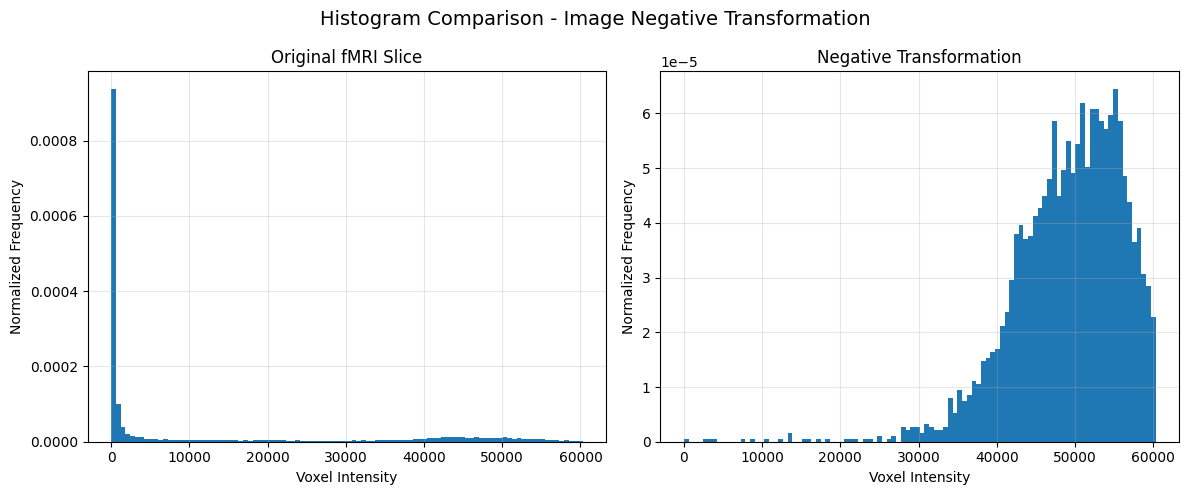

In [38]:
# ============================================================
# IMAGE NEGATIVE TRANSFORMATION
# Step 4: Histogram Comparison
# ============================================================

plt.figure(figsize=(12, 5))

# Use the same intensity range for both histograms
hist_max = np.percentile(original_slice, 99)

# Original histogram
plt.subplot(1, 2, 1)

plt.hist(
    original_slice.flatten(),
    bins=100,
    range=(0, hist_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original fMRI Slice")
plt.grid(alpha=0.3)


# Negative histogram
plt.subplot(1, 2, 2)

plt.hist(
    negative_image.flatten(),
    bins=100,
    range=(0, hist_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Negative Transformation")
plt.grid(alpha=0.3)

plt.suptitle(
    "Histogram Comparison - Image Negative Transformation",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis — Image Negative

The effect of the negative transformation is quantified using
basic intensity statistics and image-difference measures.

The mean and standard deviation describe changes in the intensity
distribution.

MSE measures the numerical difference between the original and
negative images. PSNR is also calculated for consistency with the
previous quantization experiment, but it should not be interpreted
as a reconstruction-quality measure here because the negative
transformation is intentionally designed to change the intensity
values.

The correlation coefficient is used to demonstrate the inverse
relationship between the original and negative images.

In [39]:
# ============================================================
# IMAGE NEGATIVE TRANSFORMATION
# Step 5: Quantitative Analysis
# ============================================================

# Basic intensity statistics
original_mean = np.mean(original_slice)
original_std = np.std(original_slice)

negative_mean = np.mean(negative_image)
negative_std = np.std(negative_image)

# MSE
mse_negative = np.mean(
    (original_slice - negative_image) ** 2
)

# PSNR
data_range = (
    original_slice.max() -
    original_slice.min()
)

if mse_negative == 0:
    psnr_negative = float("inf")
else:
    psnr_negative = 10 * np.log10(
        (data_range ** 2) / mse_negative
    )

# Correlation
correlation = np.corrcoef(
    original_slice.flatten(),
    negative_image.flatten()
)[0, 1]

print("Original Mean       :", original_mean)
print("Negative Mean       :", negative_mean)

print("Original Std Dev    :", original_std)
print("Negative Std Dev    :", negative_std)

print("MSE                 :", mse_negative)
print("PSNR (dB)           :", psnr_negative)

print("Correlation         :", correlation)

Original Mean       : 11951.411672484828
Negative Mean       : 85690.17407046561
Original Std Dev    : 19374.41934643445
Negative Std Dev    : 19374.41934643445
MSE                 : 6938877580.031839
PSNR (dB)           : 1.3798042241133275
Correlation         : -1.0


## Interpretation — Image Negative Transformation

The image negative transformation successfully inverted the
intensity values of the NeuroEmo fMRI slice.

The visual comparison showed that dark regions in the original
image became bright, while bright regions became dark.

The histogram analysis demonstrated a reversal of the intensity
distribution.

The standard deviation remained unchanged at approximately
19374.42, indicating that the spread of intensity values was
preserved.

The mean intensity changed from approximately 11951.41 to
85690.17 because the intensity values were reflected around the
image intensity range.

The Pearson correlation coefficient was -1.0, demonstrating a
perfect inverse linear relationship between the original and
negative-transformed images.

The MSE and PSNR values indicate a large numerical difference
between the two images. However, these metrics should not be
interpreted as image-quality measures in this case because the
negative transformation is intentionally designed to alter the
intensity representation.

### Conclusion

The experiment demonstrates the fundamental DIP concept of
intensity inversion using a real NeuroEmo fMRI image.

# Intensity Transformations

## 2. Log Transformation

### Reference

Gonzalez, R. C., & Woods, R. E.
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Intensity Transformations.

### Concept

The logarithmic transformation is used to expand the range of
dark intensity values while compressing higher intensity values.

The standard logarithmic transformation is:

s = c log(1 + r)

where:

- r = input intensity
- s = output intensity
- c = scaling constant

For the floating-point fMRI image, the intensity values are first
normalized to the range [0, 1]. The logarithmic transformation is
then applied and the result is scaled back to the original
intensity range.

The transformation is particularly useful for demonstrating how
low-intensity information can be enhanced while high-intensity
values are compressed.

### Objective

- Apply logarithmic intensity transformation to real NeuroEmo fMRI data.
- Enhance the representation of lower-intensity regions.
- Observe compression of high-intensity values.
- Compare the original and transformed images.
- Analyze the change in the intensity histogram.

In [40]:
# ============================================================
# LOG TRANSFORMATION
# Step 1: Prepare the original fMRI slice
# ============================================================

volume_0 = fmri_data[:, :, :, 0]

z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape     :", fmri_data.shape)
print("3D volume shape   :", volume_0.shape)
print("2D slice shape    :", original_slice.shape)
print("Minimum intensity :", original_slice.min())
print("Maximum intensity :", original_slice.max())

4D fMRI shape     : (128, 128, 36, 200)
3D volume shape   : (128, 128, 36)
2D slice shape    : (128, 128)
Minimum intensity : 0.0
Maximum intensity : 97641.58574295044


In [41]:
# ============================================================
# LOG TRANSFORMATION
# Step 2: Apply Logarithmic Transformation
# ============================================================

image_min = original_slice.min()
image_max = original_slice.max()

# Normalize image to [0, 1]
normalized_image = (
    (original_slice - image_min) /
    (image_max - image_min)
)

# Apply logarithmic transformation
log_image_normalized = np.log1p(
    normalized_image
)

# Normalize transformed image to [0, 1]
log_image_normalized = (
    log_image_normalized /
    log_image_normalized.max()
)

# Scale back to the original intensity range
log_image = (
    log_image_normalized *
    (image_max - image_min)
) + image_min

print("Log transformation completed.")

print("\nOriginal:")
print("Minimum :", original_slice.min())
print("Maximum :", original_slice.max())

print("\nLog transformed:")
print("Minimum :", log_image.min())
print("Maximum :", log_image.max())

Log transformation completed.

Original:
Minimum : 0.0
Maximum : 97641.58574295044

Log transformed:
Minimum : 0.0
Maximum : 97641.58574295044


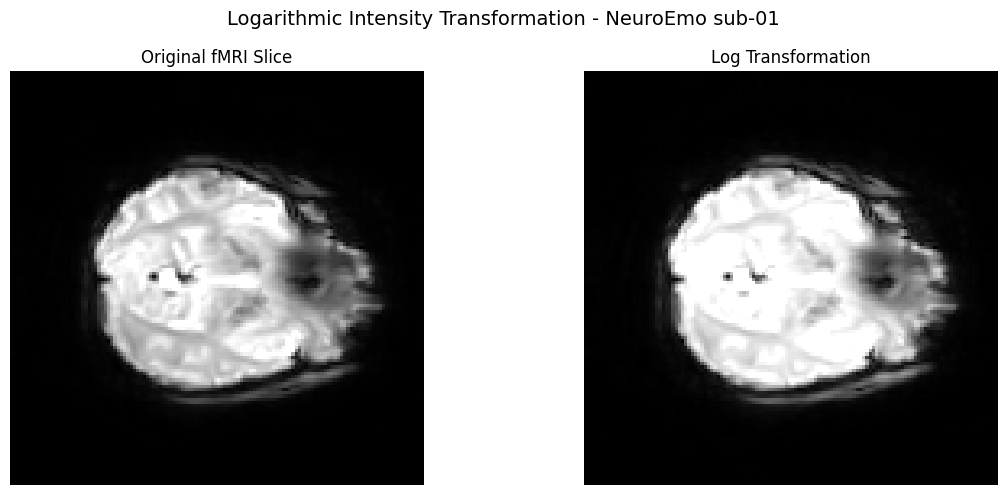

In [42]:
# ============================================================
# LOG TRANSFORMATION
# Step 3: Visual Comparison
# ============================================================

vmin = np.percentile(original_slice, 2)
vmax = np.percentile(original_slice, 98)

plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)

plt.imshow(
    original_slice,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Original fMRI Slice")
plt.axis("off")


# Log-transformed image
plt.subplot(1, 2, 2)

plt.imshow(
    log_image,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Log Transformation")
plt.axis("off")

plt.suptitle(
    "Logarithmic Intensity Transformation - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Histogram Analysis — Log Transformation

The intensity histograms of the original and logarithmically
transformed fMRI slices are compared.

The logarithmic transformation redistributes the intensity values
by expanding lower-intensity values relative to higher-intensity
values and compressing the high-intensity range.

Therefore, the histogram of the transformed image is expected
to differ substantially from the original histogram.

This demonstrates that the spatial arrangement of the image is
preserved while its intensity distribution is modified.

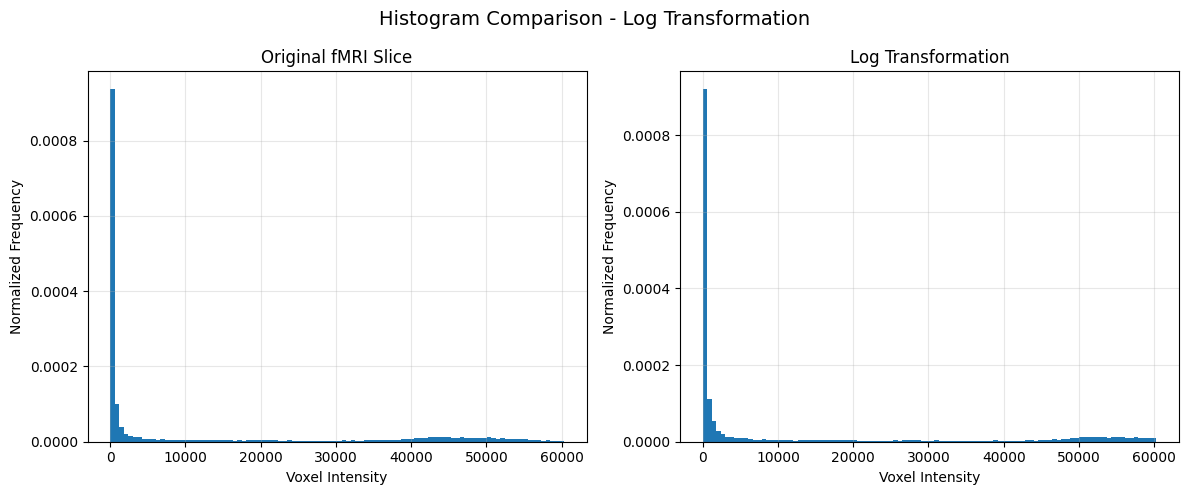

In [43]:
# ============================================================
# LOG TRANSFORMATION
# Step 4: Histogram Comparison
# ============================================================

plt.figure(figsize=(12, 5))

# Use the same range for visual comparison
hist_max = np.percentile(original_slice, 99)

# Original histogram
plt.subplot(1, 2, 1)

plt.hist(
    original_slice.flatten(),
    bins=100,
    range=(0, hist_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original fMRI Slice")
plt.grid(alpha=0.3)


# Log-transformed histogram
plt.subplot(1, 2, 2)

plt.hist(
    log_image.flatten(),
    bins=100,
    range=(0, hist_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Log Transformation")
plt.grid(alpha=0.3)

plt.suptitle(
    "Histogram Comparison - Log Transformation",
    fontsize=14
)

plt.tight_layout()
plt.show()

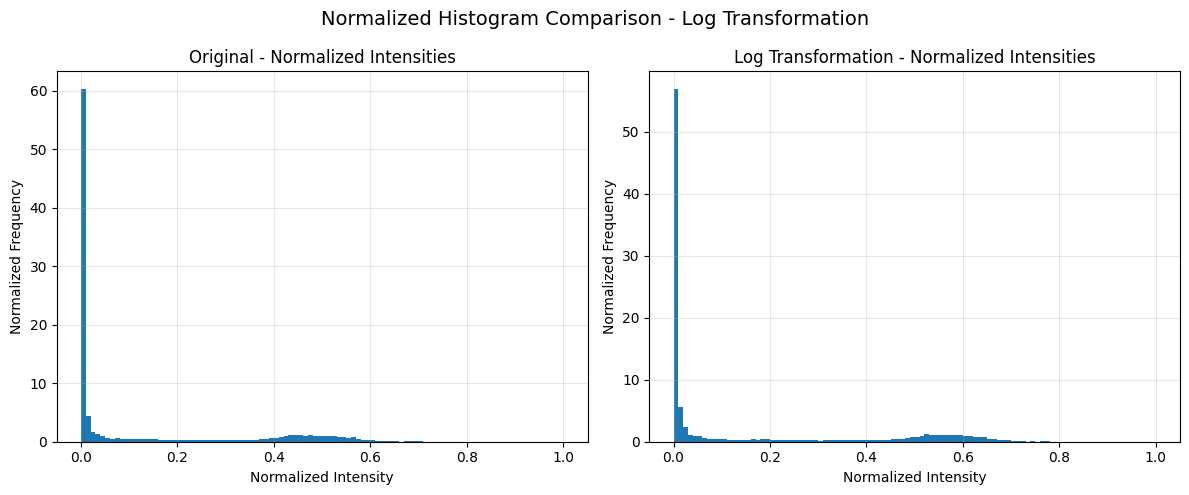

In [44]:
# ============================================================
# LOG TRANSFORMATION
# Additional Histogram Analysis
# Compare normalized intensity distributions
# ============================================================

plt.figure(figsize=(12, 5))

# Original normalized image
plt.subplot(1, 2, 1)

plt.hist(
    normalized_image.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original - Normalized Intensities")
plt.grid(alpha=0.3)


# Log-transformed normalized image
plt.subplot(1, 2, 2)

plt.hist(
    log_image_normalized.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Log Transformation - Normalized Intensities")
plt.grid(alpha=0.3)

plt.suptitle(
    "Normalized Histogram Comparison - Log Transformation",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis — Log Transformation

The effect of the logarithmic transformation is quantified using
basic intensity statistics and image-difference measures.

The mean and standard deviation are calculated to observe changes
in the intensity distribution.

MSE and PSNR are calculated to quantify the numerical difference
between the original and transformed images. However, these
metrics should not be interpreted as reconstruction-quality
measures because the log transformation is intentionally designed
to modify the intensity representation.

The Pearson correlation coefficient is also calculated to measure
the linear relationship between the original and transformed
intensities.

In [45]:
# ============================================================
# LOG TRANSFORMATION
# Step 5: Quantitative Analysis
# ============================================================

# Basic intensity statistics
original_mean = np.mean(original_slice)
original_std = np.std(original_slice)

log_mean = np.mean(log_image)
log_std = np.std(log_image)

# Mean Squared Error
mse_log = np.mean(
    (original_slice - log_image) ** 2
)

# PSNR
data_range = (
    original_slice.max() -
    original_slice.min()
)

if mse_log == 0:
    psnr_log = float("inf")
else:
    psnr_log = 10 * np.log10(
        (data_range ** 2) / mse_log
    )

# Pearson correlation
correlation_log = np.corrcoef(
    original_slice.flatten(),
    log_image.flatten()
)[0, 1]

print("Original Mean       :", original_mean)
print("Log Mean            :", log_mean)

print("Original Std Dev    :", original_std)
print("Log Std Dev         :", log_std)

print("MSE                 :", mse_log)
print("PSNR (dB)           :", psnr_log)

print("Correlation         :", correlation_log)

Original Mean       : 11951.411672484828
Log Mean            : 14327.268810123447
Original Std Dev    : 19374.41934643445
Log Std Dev         : 22629.37067035173
MSE                 : 17221973.135366533
PSNR (dB)           : 27.431867404397995
Correlation         : 0.9988794496032064


## Interpretation — Log Transformation

The logarithmic intensity transformation was successfully applied
to the NeuroEmo fMRI slice.

The visual comparison showed that the logarithmic transformation
redistributed the intensity values while preserving the overall
spatial structure of the brain.

The normalized histogram demonstrated that the transformation
redistributed the intensity distribution and compressed the
high-intensity range relative to the lower-intensity values.

The mean intensity changed from approximately 11951.41 to
14327.27, while the standard deviation changed from approximately
19374.42 to 22629.37. These changes are dependent on the
normalization and rescaling procedure used in this experiment.

The Pearson correlation coefficient was 0.99888, indicating a
very strong positive relationship between the original and
log-transformed intensities.

The MSE was approximately 1.72 × 10^7 and the PSNR was
approximately 27.43 dB. These values quantify the numerical
difference introduced by the transformation, but they should
not be interpreted as reconstruction-quality measures because
the logarithmic transformation intentionally modifies the
intensity representation.

### Conclusion

The experiment demonstrates how logarithmic transformation can
modify the dynamic range of fMRI intensities while preserving
the underlying spatial structure of the image.

# Intensity Transformations

## 3. Power-Law / Gamma Transformation

### Reference

Gonzalez, R. C., & Woods, R. E.
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Intensity Transformations.

### Concept

The power-law transformation, also called gamma transformation,
is defined as:

s = c r^γ

where:

- r = normalized input intensity
- s = output intensity
- c = scaling constant
- γ = gamma value

The value of γ controls the transformation:

- γ < 1 → expands lower intensity values
- γ = 1 → approximately preserves the input
- γ > 1 → suppresses lower intensity values and emphasizes
  relatively higher intensities

For the fMRI image, the intensity values are first normalized
to the range [0, 1]. Different gamma values are then applied
to demonstrate their effect on image appearance and intensity
distribution.

### Objective

- Apply power-law transformation to real NeuroEmo fMRI data.
- Study the effect of different gamma values.
- Compare gamma values below, equal to, and above 1.
- Analyze the resulting intensity distributions.
- Quantify the difference between the original and transformed
  images.

In [46]:
# ============================================================
# GAMMA / POWER-LAW TRANSFORMATION
# Step 1: Prepare the original fMRI slice
# ============================================================

volume_0 = fmri_data[:, :, :, 0]

z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape     :", fmri_data.shape)
print("3D volume shape   :", volume_0.shape)
print("2D slice shape    :", original_slice.shape)
print("Minimum intensity :", original_slice.min())
print("Maximum intensity :", original_slice.max())

4D fMRI shape     : (128, 128, 36, 200)
3D volume shape   : (128, 128, 36)
2D slice shape    : (128, 128)
Minimum intensity : 0.0
Maximum intensity : 97641.58574295044


In [47]:
# ============================================================
# GAMMA / POWER-LAW TRANSFORMATION
# Step 2: Apply Different Gamma Values
# ============================================================

image_min = original_slice.min()
image_max = original_slice.max()

# Normalize original image to [0, 1]
normalized_image = (
    (original_slice - image_min) /
    (image_max - image_min)
)

# Apply gamma transformations
gamma_05 = np.power(normalized_image, 0.5)
gamma_10 = np.power(normalized_image, 1.0)
gamma_20 = np.power(normalized_image, 2.0)

# Scale back to original intensity range
gamma_05_image = (
    gamma_05 * (image_max - image_min)
) + image_min

gamma_10_image = (
    gamma_10 * (image_max - image_min)
) + image_min

gamma_20_image = (
    gamma_20 * (image_max - image_min)
) + image_min

print("Gamma transformation completed.")

print("\nOriginal:")
print("Minimum :", original_slice.min())
print("Maximum :", original_slice.max())

print("\nGamma = 0.5:")
print("Minimum :", gamma_05_image.min())
print("Maximum :", gamma_05_image.max())

print("\nGamma = 1.0:")
print("Minimum :", gamma_10_image.min())
print("Maximum :", gamma_10_image.max())

print("\nGamma = 2.0:")
print("Minimum :", gamma_20_image.min())
print("Maximum :", gamma_20_image.max())

Gamma transformation completed.

Original:
Minimum : 0.0
Maximum : 97641.58574295044

Gamma = 0.5:
Minimum : 0.0
Maximum : 97641.58574295044

Gamma = 1.0:
Minimum : 0.0
Maximum : 97641.58574295044

Gamma = 2.0:
Minimum : 0.0
Maximum : 97641.58574295044


## Visual Comparison — Gamma Transformation

The original fMRI slice is compared with images transformed using
different gamma values.

Three gamma values are used:

- γ = 0.5: expands lower intensity values.
- γ = 1.0: preserves the normalized intensity values.
- γ = 2.0: compresses lower intensity values.

The same display range is used for all images to provide a
consistent visual comparison.

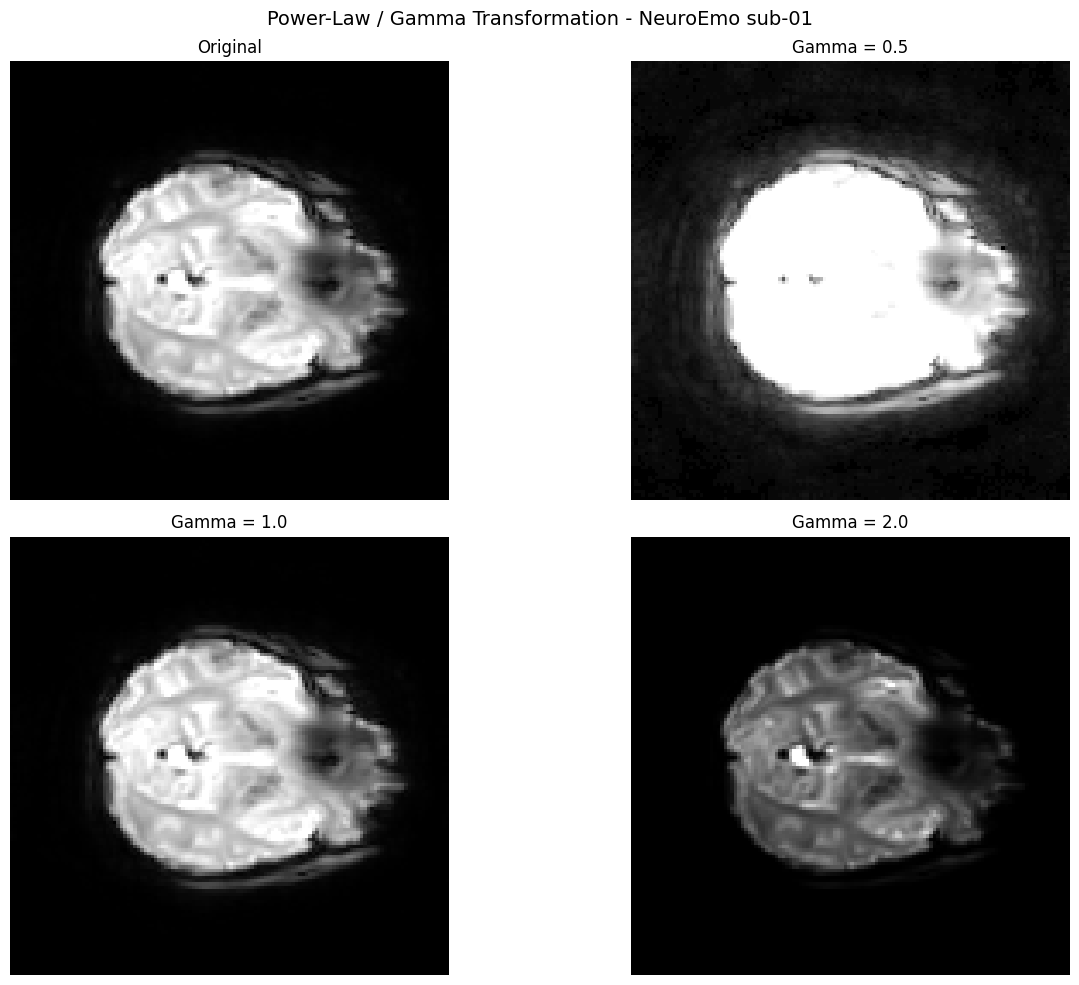

In [48]:
# ============================================================
# GAMMA / POWER-LAW TRANSFORMATION
# Step 3: Visual Comparison
# ============================================================

vmin = np.percentile(original_slice, 2)
vmax = np.percentile(original_slice, 98)

images = [
    original_slice,
    gamma_05_image,
    gamma_10_image,
    gamma_20_image
]

titles = [
    "Original",
    "Gamma = 0.5",
    "Gamma = 1.0",
    "Gamma = 2.0"
]

plt.figure(figsize=(14, 10))

for i, (image, title) in enumerate(
    zip(images, titles), 1
):

    plt.subplot(2, 2, i)

    plt.imshow(
        image,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    plt.title(title)
    plt.axis("off")

plt.suptitle(
    "Power-Law / Gamma Transformation - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Histogram Analysis — Gamma Transformation

The histograms of the original and gamma-transformed images are
compared for γ = 0.5, γ = 1.0, and γ = 2.0.

Gamma values below 1 expand lower intensity values, causing the
intensity distribution to shift toward higher output values.

A gamma value of 1 preserves the normalized intensity values.

Gamma values above 1 compress lower intensity values, causing the
output distribution to shift toward lower intensities.

The histogram comparison demonstrates how the power-law
transformation controls the dynamic range of the image.

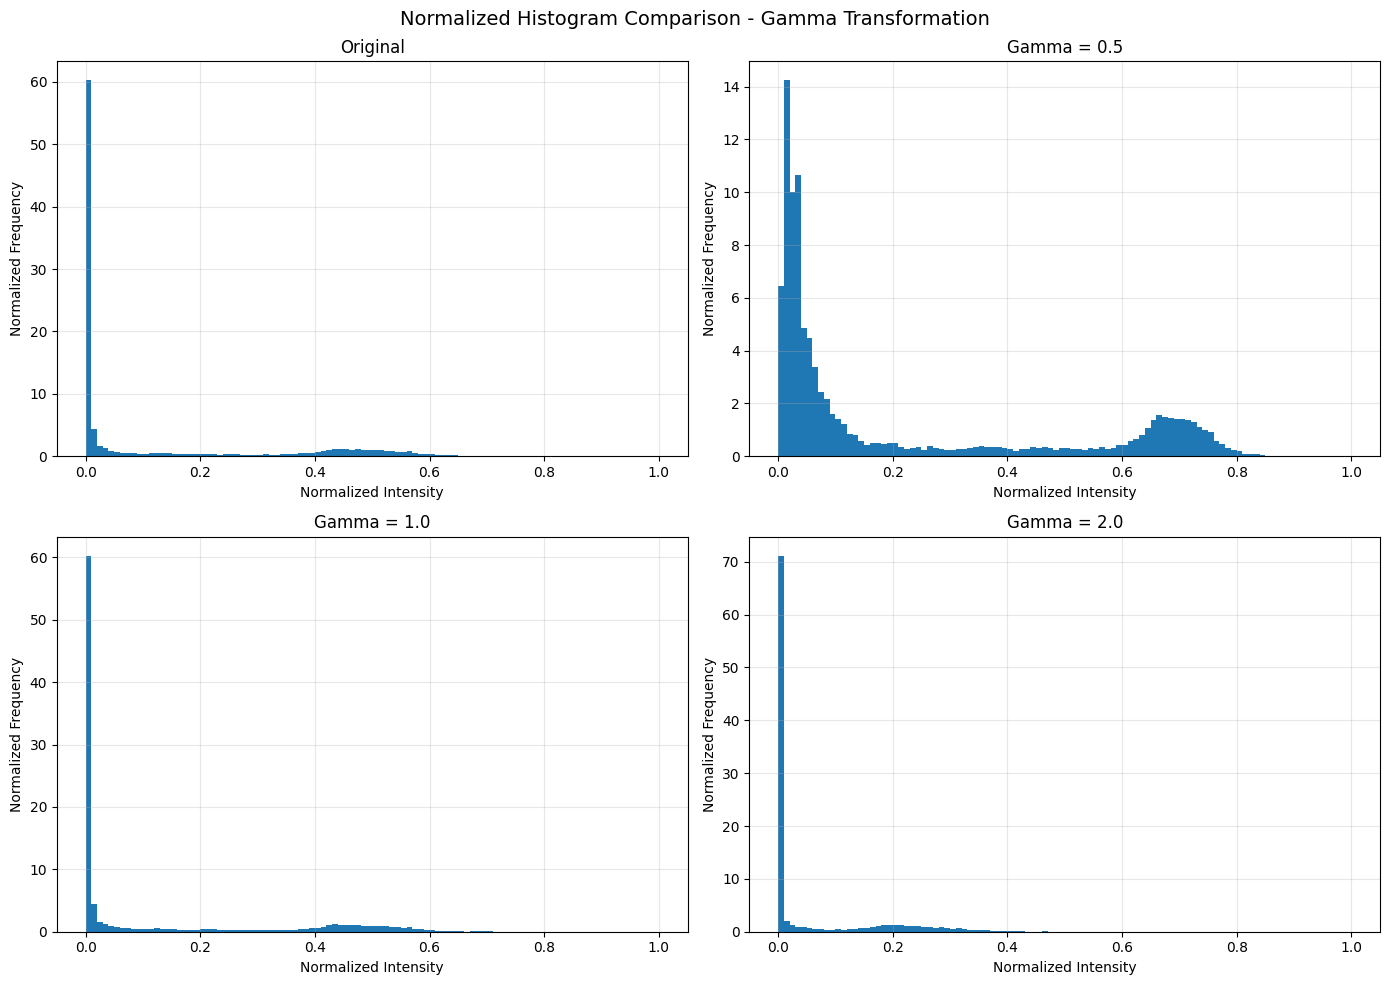

In [49]:
# ============================================================
# GAMMA / POWER-LAW TRANSFORMATION
# Step 4: Histogram Comparison
# ============================================================

plt.figure(figsize=(14, 10))

# Original
plt.subplot(2, 2, 1)

plt.hist(
    normalized_image.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original")
plt.grid(alpha=0.3)


# Gamma = 0.5
plt.subplot(2, 2, 2)

plt.hist(
    gamma_05.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Gamma = 0.5")
plt.grid(alpha=0.3)


# Gamma = 1.0
plt.subplot(2, 2, 3)

plt.hist(
    gamma_10.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Gamma = 1.0")
plt.grid(alpha=0.3)


# Gamma = 2.0
plt.subplot(2, 2, 4)

plt.hist(
    gamma_20.flatten(),
    bins=100,
    range=(0, 1),
    density=True
)

plt.xlabel("Normalized Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Gamma = 2.0")
plt.grid(alpha=0.3)


plt.suptitle(
    "Normalized Histogram Comparison - Gamma Transformation",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis — Gamma Transformation

The effect of different gamma values is quantified using mean,
standard deviation, MSE, PSNR, and Pearson correlation.

The gamma-transformed images are intentionally different from the
original image, so MSE and PSNR quantify the magnitude of the
intensity change rather than reconstruction quality.

Gamma = 1 is expected to produce an identical image because:

s = r^1 = r

Therefore, its MSE should be approximately zero and its PSNR
should be infinite (or numerically extremely large).

In [50]:
# ============================================================
# GAMMA / POWER-LAW TRANSFORMATION
# Step 5: Quantitative Analysis
# ============================================================

gamma_results = []

gamma_images = {
    0.5: gamma_05_image,
    1.0: gamma_10_image,
    2.0: gamma_20_image
}

for gamma, image in gamma_images.items():

    # Basic statistics
    mean_value = np.mean(image)
    std_value = np.std(image)

    # MSE
    mse = np.mean(
        (original_slice - image) ** 2
    )

    # PSNR
    data_range = (
        original_slice.max() -
        original_slice.min()
    )

    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10(
            (data_range ** 2) / mse
        )

    # Pearson correlation
    correlation = np.corrcoef(
        original_slice.flatten(),
        image.flatten()
    )[0, 1]

    gamma_results.append({
        "Gamma": gamma,
        "Mean": mean_value,
        "Std Dev": std_value,
        "MSE": mse,
        "PSNR (dB)": psnr,
        "Correlation": correlation
    })

gamma_df = pd.DataFrame(gamma_results)

gamma_df

,Gamma,Mean,Std Dev,MSE,PSNR (dB),Correlation
0,0.5,21555.063457,26501.585366,1.636153e+08,17.654456,0.979951
1,1.0,11951.411672,19374.419346,1.474277e-24,338.106906,1.000000
2,2.0,5307.209649,10214.931977,1.400579e+08,18.329622,0.969642


## Interpretation — Power-Law / Gamma Transformation

The power-law transformation was successfully applied to the
NeuroEmo fMRI slice using three gamma values: 0.5, 1.0, and 2.0.

For γ = 0.5, lower intensity values were expanded, resulting in
a brighter image and an increase in the mean intensity from
approximately 11951.41 to 21555.06.

For γ = 1.0, the transformation behaves as an identity operation
because r^1 = r. The MSE was approximately zero and the
correlation coefficient was 1.0, confirming that the image was
essentially unchanged. The calculated PSNR of 338.11 dB is a
floating-point representation of an effectively infinite PSNR.

For γ = 2.0, lower intensity values were compressed, producing a
darker image and reducing the mean intensity to approximately
5307.21.

The histogram analysis also demonstrated the redistribution of
intensity values for different gamma values.

The correlation coefficients remained strongly positive for both
γ = 0.5 and γ = 2.0 because the power-law transformation is
monotonically increasing and preserves the ordering of intensity
values.

MSE and PSNR quantify the numerical difference introduced by the
transformation, but they should not be interpreted as image
quality measures because the gamma transformation intentionally
changes the intensity representation.

### Conclusion

The experiment demonstrates how the gamma parameter controls
image brightness and intensity distribution:

- γ < 1 expands lower intensities.
- γ = 1 preserves the image.
- γ > 1 compresses lower intensities.

Thus, power-law transformation provides controlled adjustment
of the intensity representation of the fMRI image.

# Intensity Transformations

## 4. Piecewise-Linear Transformation — Contrast Stretching

### Reference

Gonzalez, R. C., & Woods, R. E.
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Intensity Transformations — Piecewise-Linear
Transformation.

### Concept

Piecewise-linear transformations use different linear functions
over different ranges of input intensity values.

Contrast stretching is a piecewise-linear transformation used to
expand a limited intensity range so that the image uses a wider
range of available intensities.

A simple contrast-stretching transformation can be represented as:

        0,                    r < r1

s =     (s2-s1)/(r2-r1)(r-r1)+s1,   r1 ≤ r ≤ r2

        L-1,                  r > r2

where:

- r = input intensity
- s = output intensity
- r1, r2 = input intensity control points
- s1, s2 = corresponding output intensity values
- L = number of possible intensity levels

For this experiment, the fMRI intensities are first normalized
to [0, 1]. Lower and upper intensity control points are selected
using percentiles of the image.

### Objective

- Apply contrast stretching to a real NeuroEmo fMRI slice.
- Expand the useful intensity range.
- Improve the visual representation of intensity differences.
- Compare the original and contrast-stretched images.
- Analyze the corresponding histogram changes.
- Quantify the transformation using statistical measures.

In [51]:
# ============================================================
# CONTRAST STRETCHING
# Step 1: Prepare the original fMRI slice
# ============================================================

volume_0 = fmri_data[:, :, :, 0]

z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape     :", fmri_data.shape)
print("3D volume shape   :", volume_0.shape)
print("2D slice shape    :", original_slice.shape)
print("Minimum intensity :", original_slice.min())
print("Maximum intensity :", original_slice.max())

4D fMRI shape     : (128, 128, 36, 200)
3D volume shape   : (128, 128, 36)
2D slice shape    : (128, 128)
Minimum intensity : 0.0
Maximum intensity : 97641.58574295044


## Contrast Stretching — Control Points

To reduce the influence of extreme intensity values, the 5th and
95th percentiles of the fMRI slice are used as the input control
points.

The lower control point is mapped to 0 and the upper control point
is mapped to 1.

Pixels below the lower control point are clipped to 0, while pixels
above the upper control point are clipped to 1.

This expands the intensity range of the main portion of the image.

In [52]:
# ============================================================
# CONTRAST STRETCHING
# Step 2: Determine Control Points
# ============================================================

# Calculate lower and upper intensity control points
r1 = np.percentile(original_slice, 5)
r2 = np.percentile(original_slice, 95)

print("Contrast Stretching Control Points")
print("----------------------------------")
print("Minimum intensity :", original_slice.min())
print("5th percentile    :", r1)
print("95th percentile   :", r2)
print("Maximum intensity :", original_slice.max())

Contrast Stretching Control Points
----------------------------------
Minimum intensity : 0.0
5th percentile    : 0.0
95th percentile   : 52355.411098480225
Maximum intensity : 97641.58574295044


## Applying Contrast Stretching

The contrast-stretching transformation maps the selected input
range [r1, r2] to the full output intensity range.

The transformation is:

s = ((r - r1) / (r2 - r1)) × (s_max - s_min) + s_min

where:

- r1 = 5th percentile of the input image
- r2 = 95th percentile of the input image
- s_min = minimum output intensity
- s_max = maximum output intensity

Input values below r1 are mapped to s_min, while values above r2
are mapped to s_max.

For this fMRI slice, r1 = 0 and r2 ≈ 52355.41.

In [53]:
# ============================================================
# CONTRAST STRETCHING
# Step 3: Apply Piecewise-Linear Contrast Stretching
# ============================================================

# Output intensity range
s_min = original_slice.min()
s_max = original_slice.max()

# Clip input intensities to the selected control-point range
clipped_image = np.clip(
    original_slice,
    r1,
    r2
)

# Apply contrast stretching
contrast_stretched = (
    (clipped_image - r1) /
    (r2 - r1)
) * (s_max - s_min) + s_min

print("Contrast stretching completed.")

print("\nOriginal:")
print("Minimum :", original_slice.min())
print("Maximum :", original_slice.max())

print("\nContrast Stretched:")
print("Minimum :", contrast_stretched.min())
print("Maximum :", contrast_stretched.max())

print("\nControl Points:")
print("r1 =", r1)
print("r2 =", r2)

Contrast stretching completed.

Original:
Minimum : 0.0
Maximum : 97641.58574295044

Contrast Stretched:
Minimum : 0.0
Maximum : 97641.58574295044

Control Points:
r1 = 0.0
r2 = 52355.411098480225


## Visual Comparison — Contrast Stretching

The original fMRI slice is compared with the contrast-stretched
image.

The intensity range between the selected lower and upper control
points is expanded to the full output intensity range.

For this image:

- Lower control point (r1) = 0
- Upper control point (r2) ≈ 52355.41

Intensity values above the upper control point are saturated at
the maximum output intensity.

The comparison demonstrates how contrast stretching increases
the separation between intensity values within the selected range.

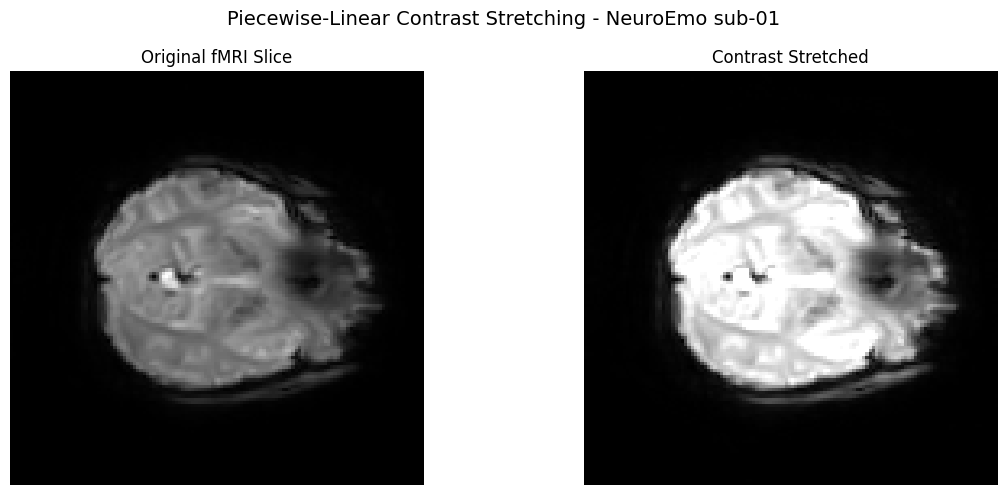

In [54]:
# ============================================================
# CONTRAST STRETCHING
# Step 4: Visual Comparison
# ============================================================

# Use the full output range because contrast stretching itself
# changes the intensity range.
vmin = original_slice.min()
vmax = original_slice.max()

plt.figure(figsize=(12, 5))

# Original
plt.subplot(1, 2, 1)

plt.imshow(
    original_slice,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Original fMRI Slice")
plt.axis("off")


# Contrast stretched
plt.subplot(1, 2, 2)

plt.imshow(
    contrast_stretched,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)

plt.title("Contrast Stretched")
plt.axis("off")


plt.suptitle(
    "Piecewise-Linear Contrast Stretching - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Histogram Analysis — Contrast Stretching

The histograms of the original and contrast-stretched fMRI slices
are compared.

Contrast stretching expands the selected input intensity range
toward the full output range. Therefore, the transformed histogram
is expected to occupy a wider intensity range than the original.

Because the upper control point was selected at the 95th percentile,
intensities above this point are mapped to the maximum output
intensity, producing a concentration near the upper end of the
histogram.

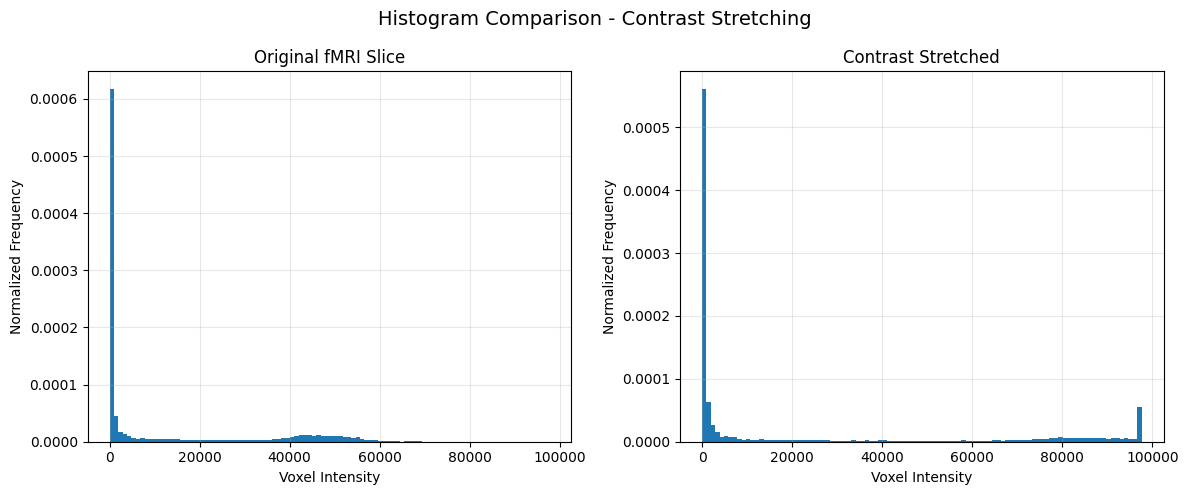

In [55]:
# ============================================================
# CONTRAST STRETCHING
# Step 5: Histogram Comparison
# ============================================================

plt.figure(figsize=(12, 5))

# Original histogram
plt.subplot(1, 2, 1)

plt.hist(
    original_slice.flatten(),
    bins=100,
    range=(0, original_slice.max()),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original fMRI Slice")
plt.grid(alpha=0.3)


# Contrast-stretched histogram
plt.subplot(1, 2, 2)

plt.hist(
    contrast_stretched.flatten(),
    bins=100,
    range=(0, contrast_stretched.max()),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Contrast Stretched")
plt.grid(alpha=0.3)

plt.suptitle(
    "Histogram Comparison - Contrast Stretching",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis — Contrast Stretching

The effect of contrast stretching is quantified using mean,
standard deviation, MSE, PSNR, and Pearson correlation.

The mean and standard deviation describe the change in the
intensity distribution.

MSE and PSNR quantify the numerical difference between the
original and contrast-stretched images. These metrics describe
the magnitude of the transformation and should not be interpreted
as reconstruction-quality measures because contrast stretching
intentionally modifies the intensity values.

The Pearson correlation measures the relationship between the
original and transformed intensity values.

In [56]:
# ============================================================
# CONTRAST STRETCHING
# Step 6: Quantitative Analysis
# ============================================================

# Basic statistics
original_mean = np.mean(original_slice)
original_std = np.std(original_slice)

stretched_mean = np.mean(contrast_stretched)
stretched_std = np.std(contrast_stretched)

# Mean Squared Error
mse_stretch = np.mean(
    (original_slice - contrast_stretched) ** 2
)

# PSNR
data_range = (
    original_slice.max() -
    original_slice.min()
)

if mse_stretch == 0:
    psnr_stretch = float("inf")
else:
    psnr_stretch = 10 * np.log10(
        (data_range ** 2) / mse_stretch
    )

# Pearson correlation
correlation_stretch = np.corrcoef(
    original_slice.flatten(),
    contrast_stretched.flatten()
)[0, 1]

print("Original Mean       :", original_mean)
print("Stretched Mean      :", stretched_mean)

print("Original Std Dev    :", original_std)
print("Stretched Std Dev   :", stretched_std)

print("MSE                 :", mse_stretch)
print("PSNR (dB)           :", psnr_stretch)

print("Correlation         :", correlation_stretch)

Original Mean       : 11951.411672484828
Stretched Mean      : 21798.90411978538
Original Std Dev    : 19374.41934643445
Stretched Std Dev   : 34938.164005095954
MSE                 : 344095404.71568215
PSNR (dB)           : 14.425907750820063
Correlation         : 0.9963863928033871


## Interpretation — Contrast Stretching

Piecewise-linear contrast stretching was successfully applied to
the NeuroEmo fMRI slice.

The 5th percentile was 0.0 and the 95th percentile was
approximately 52355.41. These values were used as the input
control points for expanding the main intensity range.

The visual comparison showed increased contrast in the brain
region, with intensity differences becoming more pronounced.

The histogram demonstrated that the intensity distribution was
expanded toward the available output range. A concentration near
the maximum intensity was observed because values above the
95th-percentile control point were clipped to the maximum output
intensity.

The mean intensity increased from approximately 11951.41 to
21798.90, while the standard deviation increased from
approximately 19374.42 to 34938.16. This indicates a substantial
increase in the spread of intensity values.

The Pearson correlation coefficient was 0.99639, indicating a
strong positive relationship between the original and
contrast-stretched intensities.

The MSE was approximately 3.44 × 10^8 and the PSNR was
approximately 14.43 dB. These values quantify the intensity
changes introduced by the transformation and should not be
interpreted as reconstruction-quality measures.

### Conclusion

Contrast stretching successfully demonstrated a
piecewise-linear intensity transformation on real NeuroEmo fMRI
data. The experiment showed how expanding the useful intensity
range can increase the visual contrast of the image while
preserving the overall spatial structure.

# Intensity Transformations

## 6. Piecewise-Linear Transformation — Gray-Level Slicing

### Reference

Gonzalez, R. C., & Woods, R. E.
*Digital Image Processing*, 4th Edition, Pearson.

**Topic:** Intensity Transformations — Gray-Level Slicing.

### Concept

Gray-level slicing is an intensity transformation used to
highlight a specific range of intensity values in an image.

Instead of treating all intensity values equally, a selected
intensity interval is emphasized while the remaining intensities
are suppressed or preserved.

For an input intensity r, a simple binary gray-level slicing
transformation can be represented as:

    s = 1,  if A ≤ r ≤ B
    s = 0,  otherwise

where A and B define the selected intensity range.

A second approach preserves the original intensity outside the
selected range:

    s = L-1,  if A ≤ r ≤ B
    s = r,    otherwise

In this experiment, gray-level slicing is applied to a real
NeuroEmo fMRI slice to demonstrate how a selected intensity range
can be isolated.

### Objective

- Apply gray-level slicing to a real fMRI image.
- Select and highlight a meaningful intensity range.
- Produce a binary/sliced representation of the selected range.
- Compare the original and sliced images.
- Analyze the selected intensity distribution.

In [57]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 1: Prepare the original fMRI slice
# ============================================================

volume_0 = fmri_data[:, :, :, 0]

z = volume_0.shape[2] // 2

original_slice = volume_0[:, :, z].copy()

print("4D fMRI shape     :", fmri_data.shape)
print("3D volume shape   :", volume_0.shape)
print("2D slice shape    :", original_slice.shape)
print("Minimum intensity :", original_slice.min())
print("Maximum intensity :", original_slice.max())

4D fMRI shape     : (128, 128, 36, 200)
3D volume shape   : (128, 128, 36)
2D slice shape    : (128, 128)
Minimum intensity : 0.0
Maximum intensity : 97641.58574295044


## Gray-Level Slicing — Selecting the Intensity Range

The NeuroEmo fMRI slice contains a large number of background
voxels with intensity 0 and a strongly skewed intensity
distribution.

Therefore, the slicing range is selected using percentiles of the
actual fMRI slice rather than arbitrary intensity values.

The selected range will focus on the central portion of the
non-background intensity distribution.

In [58]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 2: Analyze Intensity Percentiles
# ============================================================

# Extract non-zero voxels
nonzero_values = original_slice[original_slice > 0]

percentiles = [10, 25, 50, 75, 90, 95]

print("Intensity Percentiles — Non-zero Voxels")
print("----------------------------------------")

for p in percentiles:
    value = np.percentile(nonzero_values, p)
    print(f"{p:>3}th percentile : {value:.2f}")

Intensity Percentiles — Non-zero Voxels
----------------------------------------
 10th percentile : 35.88
 25th percentile : 71.77
 50th percentile : 430.61
 75th percentile : 23576.08
 90th percentile : 47762.20
 95th percentile : 52786.02


## Gray-Level Slicing — Binary Slicing

A binary gray-level slicing transformation is applied to isolate
voxels whose intensities fall within the selected range.

The selected intensity interval is:

    23576.08 ≤ r ≤ 52786.02

Voxels within this range are assigned a value of 1, while all
other voxels are assigned 0.

This produces a binary representation of the selected intensity
band.

In [59]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 3: Apply Binary Gray-Level Slicing
# ============================================================

# Select intensity range based on non-zero percentiles
lower_level = np.percentile(nonzero_values, 75)
upper_level = np.percentile(nonzero_values, 95)

# Create binary gray-level sliced image
gray_slice_binary = np.where(
    (original_slice >= lower_level) &
    (original_slice <= upper_level),
    1,
    0
)

print("Gray-level slicing completed.")

print("\nSelected intensity range:")
print("Lower level :", lower_level)
print("Upper level :", upper_level)

print("\nBinary sliced image:")
print("Minimum     :", gray_slice_binary.min())
print("Maximum     :", gray_slice_binary.max())

print(
    "Selected voxels :",
    np.sum(gray_slice_binary == 1)
)

print(
    "Selected percentage :",
    np.mean(gray_slice_binary == 1) * 100,
    "%"
)

Gray-level slicing completed.

Selected intensity range:
Lower level : 23576.08299636841
Upper level : 52786.02448654175

Binary sliced image:
Minimum     : 0
Maximum     : 1
Selected voxels : 3071
Selected percentage : 18.743896484375 %


## Visual Comparison — Gray-Level Slicing

The original fMRI slice is compared with the binary gray-level
sliced image.

Only voxels whose intensities fall within the selected range
[23576.08, 52786.02] are highlighted.

All other intensity values are suppressed.

The resulting binary image shows the spatial locations of voxels
belonging to the selected intensity band.

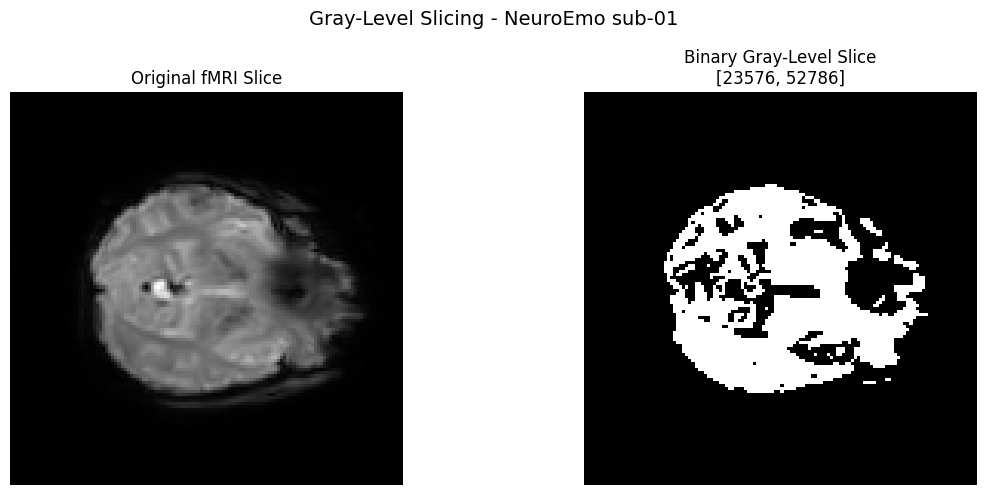

In [60]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 4: Visual Comparison
# ============================================================

plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)

plt.imshow(
    original_slice,
    cmap="gray",
    origin="lower"
)

plt.title("Original fMRI Slice")
plt.axis("off")


# Binary gray-level sliced image
plt.subplot(1, 2, 2)

plt.imshow(
    gray_slice_binary,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=1
)

plt.title(
    "Binary Gray-Level Slice\n"
    f"[{lower_level:.0f}, {upper_level:.0f}]"
)

plt.axis("off")

plt.suptitle(
    "Gray-Level Slicing - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Histogram Analysis — Gray-Level Slicing

The histogram of the original fMRI slice is compared with the
intensity distribution of the selected gray-level range.

The selected interval is defined using the 75th and 95th
percentiles of the non-zero voxel intensities.

Gray-level slicing isolates this intensity interval while
suppressing all other intensity values.

The histogram demonstrates which portion of the original intensity
distribution has been selected.

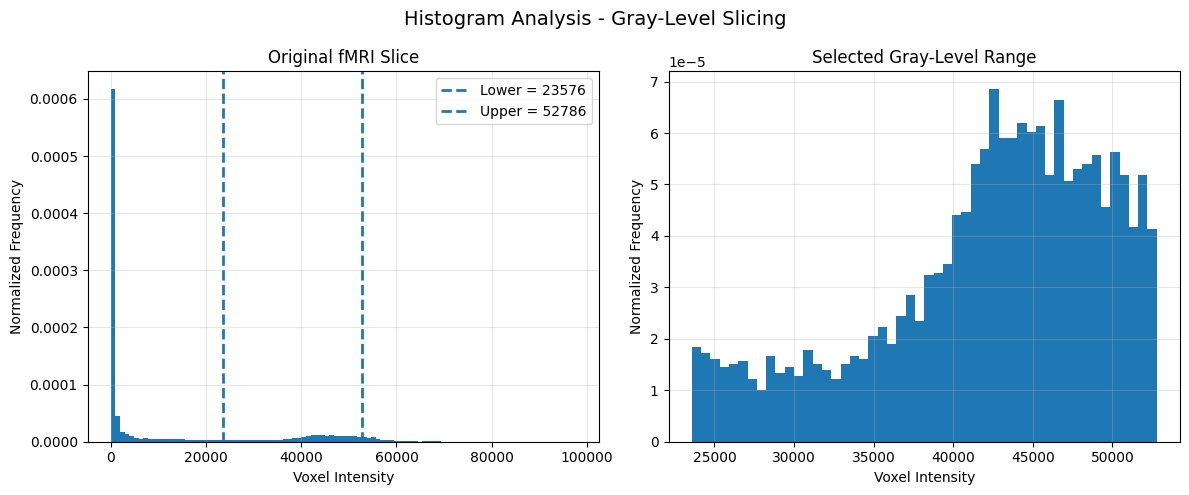

In [61]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 5: Histogram Analysis
# ============================================================

plt.figure(figsize=(12, 5))

# Original histogram
plt.subplot(1, 2, 1)

plt.hist(
    original_slice.flatten(),
    bins=100,
    range=(0, original_slice.max()),
    density=True
)

plt.axvline(
    lower_level,
    linestyle="--",
    linewidth=2,
    label=f"Lower = {lower_level:.0f}"
)

plt.axvline(
    upper_level,
    linestyle="--",
    linewidth=2,
    label=f"Upper = {upper_level:.0f}"
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Original fMRI Slice")
plt.legend()
plt.grid(alpha=0.3)


# Selected intensity values
selected_values = original_slice[
    gray_slice_binary == 1
]

plt.subplot(1, 2, 2)

plt.hist(
    selected_values,
    bins=50,
    range=(lower_level, upper_level),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Selected Gray-Level Range")
plt.grid(alpha=0.3)

plt.suptitle(
    "Histogram Analysis - Gray-Level Slicing",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis — Gray-Level Slicing

The gray-level slicing operation converts the selected intensity
range into a binary representation.

The following quantities are measured:

- Number of selected voxels
- Percentage of selected voxels
- Mean intensity of the selected voxels
- Standard deviation of the selected voxels
- Minimum and maximum selected intensity

These measurements describe the intensity characteristics of
the region isolated by gray-level slicing.

In [62]:
# ============================================================
# GRAY-LEVEL SLICING
# Step 6: Quantitative Analysis
# ============================================================

total_voxels = original_slice.size

selected_voxels = np.sum(gray_slice_binary == 1)

selected_percentage = (
    selected_voxels / total_voxels
) * 100

selected_values = original_slice[
    gray_slice_binary == 1
]

selected_mean = selected_values.mean()
selected_std = selected_values.std()
selected_min = selected_values.min()
selected_max = selected_values.max()

print("Gray-Level Slicing Quantitative Analysis")
print("-" * 50)

print(f"Total voxels             : {total_voxels}")
print(f"Selected voxels          : {selected_voxels}")
print(f"Selected percentage      : {selected_percentage:.2f}%")

print(f"Selected intensity mean  : {selected_mean:.2f}")
print(f"Selected intensity std   : {selected_std:.2f}")
print(f"Selected intensity min   : {selected_min:.2f}")
print(f"Selected intensity max   : {selected_max:.2f}")

Gray-Level Slicing Quantitative Analysis
--------------------------------------------------
Total voxels             : 16384
Selected voxels          : 3071
Selected percentage      : 18.74%
Selected intensity mean  : 42161.32
Selected intensity std   : 7324.43
Selected intensity min   : 23576.08
Selected intensity max   : 52786.02


## Interpretation — Gray-Level Slicing

Gray-level slicing successfully isolated voxels whose intensities
were within the selected range of 23,576.08 to 52,786.02.

The binary representation selected 3,071 out of 16,384 voxels,
corresponding to 18.74% of the image slice.

The selected voxels had a mean intensity of 42,161.32 and a
standard deviation of 7,324.43.

The visualization demonstrates how gray-level slicing can be used
to emphasize a specific intensity band while suppressing other
intensity values.

In this experiment, the technique is used as a Digital Image
Processing demonstration rather than as a definitive anatomical
or functional brain segmentation method.

The selected intensity range was determined from the 75th to 95th
percentiles of the non-zero voxel intensities of the representative
fMRI slice.

## Bit-Plane Slicing

### Reference

Gonzalez, R. C., & Woods, R. E.,
Digital Image Processing, 4th Edition,
Pearson.

### Theory

A digital image can be represented using binary bits for each
pixel intensity.

For an 8-bit grayscale image, each pixel is represented using
8 bits:

Bit 7  Bit 6  Bit 5  Bit 4  Bit 3  Bit 2  Bit 1  Bit 0
 MSB                                            LSB

Each bit position forms a separate binary image called a
bit-plane.

Bit-plane slicing separates an image into these individual
binary planes to analyze the contribution of different bits
to the image representation.

Higher-order bits generally contain the major structural and
intensity information, while lower-order bits generally
contain finer intensity variations and details.

Since the NeuroEmo fMRI data contains floating-point intensity
values, the representative fMRI slice is first normalized to
an 8-bit grayscale representation (0–255) before performing
bit-plane slicing.

### Objective

To decompose an actual NeuroEmo fMRI slice into its eight
8-bit bit-planes and examine how image information is
distributed across different bit positions.

In [63]:
# ============================================================
# BIT-PLANE SLICING
# Step 2: Convert fMRI Slice to 8-bit
# ============================================================

image_min = original_slice.min()
image_max = original_slice.max()

normalized_8bit = (
    (original_slice - image_min)
    / (image_max - image_min)
)

image_8bit = (
    normalized_8bit * 255
).astype(np.uint8)

print("Original fMRI slice:")
print("Shape :", original_slice.shape)
print("Min   :", original_slice.min())
print("Max   :", original_slice.max())

print("\n8-bit representation:")
print("Shape :", image_8bit.shape)
print("Min   :", image_8bit.min())
print("Max   :", image_8bit.max())
print("Dtype :", image_8bit.dtype)

Original fMRI slice:
Shape : (128, 128)
Min   : 0.0
Max   : 97641.58574295044

8-bit representation:
Shape : (128, 128)
Min   : 0
Max   : 255
Dtype : uint8


## Bit-Plane Extraction

An 8-bit grayscale image contains eight binary bit-planes,
corresponding to bit positions 0 through 7.

Bit 0 is the Least Significant Bit (LSB), while Bit 7 is the
Most Significant Bit (MSB).

Each bit-plane is extracted using a bitwise AND operation:

    bit_plane_k = (image_8bit >> k) & 1

where k represents the bit position from 0 to 7.

The resulting bit-plane contains only binary values:

    0 → bit is not set
    1 → bit is set

In [64]:
# ============================================================
# BIT-PLANE SLICING
# Step 3: Extract 8 Bit Planes
# ============================================================

bit_planes = {}

for bit in range(8):
    bit_planes[bit] = (image_8bit >> bit) & 1

# Verify the extracted planes
for bit in range(8):
    print(
        f"Bit {bit}: "
        f"shape={bit_planes[bit].shape}, "
        f"unique values={np.unique(bit_planes[bit])}"
    )

Bit 0: shape=(128, 128), unique values=[0 1]
Bit 1: shape=(128, 128), unique values=[0 1]
Bit 2: shape=(128, 128), unique values=[0 1]
Bit 3: shape=(128, 128), unique values=[0 1]
Bit 4: shape=(128, 128), unique values=[0 1]
Bit 5: shape=(128, 128), unique values=[0 1]
Bit 6: shape=(128, 128), unique values=[0 1]
Bit 7: shape=(128, 128), unique values=[0 1]


## Visualization of Bit Planes

The eight extracted bit-planes are visualized from Bit 0 (LSB)
to Bit 7 (MSB).

Bit 0 represents the least significant intensity information,
while Bit 7 represents the most significant intensity information.

Comparing the planes allows us to observe how structural and
intensity information is distributed across the binary
representation of the fMRI slice.

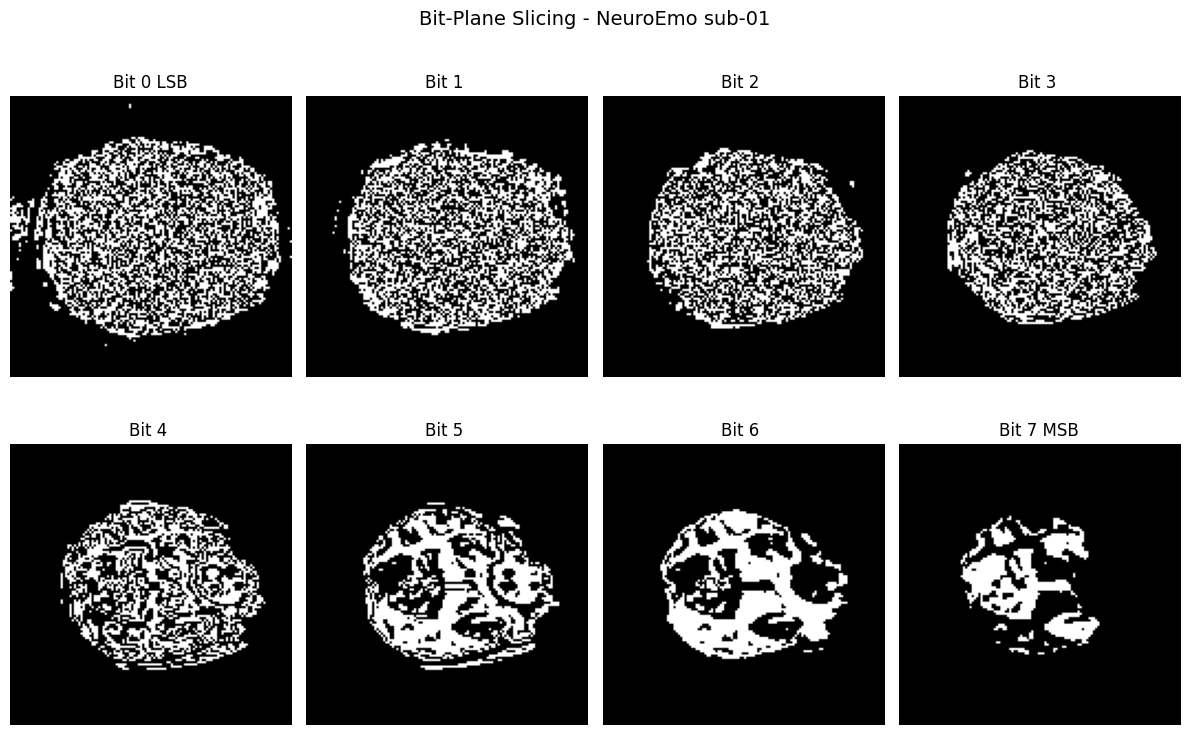

In [65]:
# ============================================================
# BIT-PLANE SLICING
# Step 4: Visualize All 8 Bit Planes
# ============================================================

plt.figure(figsize=(12, 8))

for bit in range(8):
    plt.subplot(2, 4, bit + 1)

    plt.imshow(
        bit_planes[bit],
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=1
    )

    if bit == 0:
        label = "LSB"
    elif bit == 7:
        label = "MSB"
    else:
        label = ""

    plt.title(f"Bit {bit} {label}")
    plt.axis("off")

plt.suptitle(
    "Bit-Plane Slicing - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Quantitative Analysis of Bit Planes

Each bit-plane is a binary image containing only 0 and 1.

For every bit-plane, the number and percentage of active pixels
(bit value = 1) are calculated.

A higher active-pixel percentage indicates that the corresponding
bit contributes to a larger portion of the image intensity
representation.

This provides a quantitative comparison of the information
distribution across the eight bit positions.

In [66]:
# ============================================================
# BIT-PLANE SLICING
# Step 5: Quantitative Analysis
# ============================================================

bit_plane_stats = []

total_pixels = image_8bit.size

for bit in range(8):

    plane = bit_planes[bit]

    active_pixels = np.sum(plane == 1)

    active_percentage = (
        active_pixels / total_pixels
    ) * 100

    mean_value = plane.mean()

    bit_plane_stats.append({
        "Bit": bit,
        "Active Pixels": active_pixels,
        "Active Percentage (%)": active_percentage,
        "Mean Binary Value": mean_value
    })

bit_plane_stats_df = pd.DataFrame(bit_plane_stats)

print(bit_plane_stats_df.to_string(index=False))

 Bit  Active Pixels  Active Percentage (%)  Mean Binary Value
   0           4303              26.263428           0.262634
   1           3788              23.120117           0.231201
   2           3136              19.140625           0.191406
   3           2865              17.486572           0.174866
   4           2619              15.985107           0.159851
   5           2711              16.546631           0.165466
   6           2466              15.051270           0.150513
   7           1340               8.178711           0.081787


## Image Reconstruction from Bit Planes

The original 8-bit fMRI image can be reconstructed by combining
individual bit-planes using their corresponding binary weights.

For an 8-bit image:

I(x,y) = Σ b_k(x,y) × 2^k

where b_k represents the kth bit-plane.

To study the contribution of higher-order bits, the image is
reconstructed progressively using:

- Bit 7 only
- Bits 7–6
- Bits 7–4
- Bits 7–0

The reconstructed images demonstrate how increasing the number
of bit-planes improves intensity representation and image detail.

In [67]:
# ============================================================
# BIT-PLANE SLICING
# Step 6: Progressive Image Reconstruction
# ============================================================

# Reconstruction using selected bit planes

reconstruction_bit7 = (
    bit_planes[7] * (2 ** 7)
)

reconstruction_bits76 = (
    bit_planes[7] * (2 ** 7) +
    bit_planes[6] * (2 ** 6)
)

reconstruction_bits74 = (
    bit_planes[7] * (2 ** 7) +
    bit_planes[6] * (2 ** 6) +
    bit_planes[5] * (2 ** 5) +
    bit_planes[4] * (2 ** 4)
)

reconstruction_all = np.zeros_like(
    image_8bit,
    dtype=np.uint16
)

for bit in range(8):
    reconstruction_all += (
        bit_planes[bit] * (2 ** bit)
    )

# Convert to uint8
reconstruction_bit7 = reconstruction_bit7.astype(np.uint8)
reconstruction_bits76 = reconstruction_bits76.astype(np.uint8)
reconstruction_bits74 = reconstruction_bits74.astype(np.uint8)
reconstruction_all = reconstruction_all.astype(np.uint8)

print("Reconstruction completed.")

print("Original range:",
      image_8bit.min(), "to", image_8bit.max())

print("Bit 7 range:",
      reconstruction_bit7.min(),
      "to",
      reconstruction_bit7.max())

print("Bits 7-6 range:",
      reconstruction_bits76.min(),
      "to",
      reconstruction_bits76.max())

print("Bits 7-4 range:",
      reconstruction_bits74.min(),
      "to",
      reconstruction_bits74.max())

print("All bits range:",
      reconstruction_all.min(),
      "to",
      reconstruction_all.max())

Reconstruction completed.
Original range: 0 to 255
Bit 7 range: 0 to 128
Bits 7-6 range: 0 to 192
Bits 7-4 range: 0 to 240
All bits range: 0 to 255


## Progressive Reconstruction from Bit Planes

The reconstructed images are visualized using progressively more
significant bit-planes.

The first reconstruction uses only Bit 7, followed by Bits 7–6,
Bits 7–4, and finally all eight bit-planes.

This demonstrates how higher-order bits provide the major
intensity structure, while additional lower-order bits restore
increasing levels of image detail.

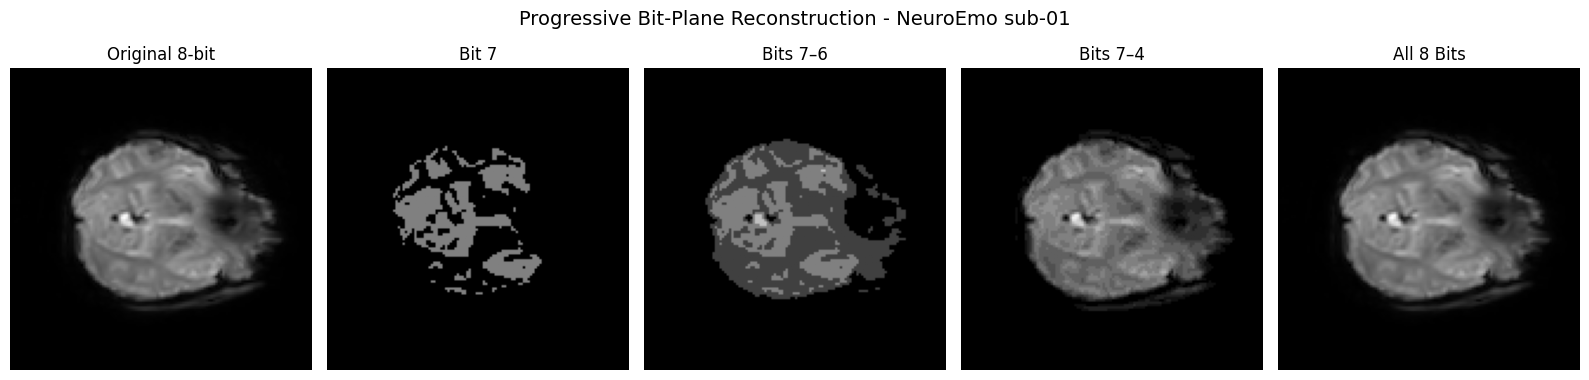

In [68]:
# ============================================================
# BIT-PLANE SLICING
# Step 7: Visualize Progressive Reconstruction
# ============================================================

plt.figure(figsize=(16, 4))

# Original
plt.subplot(1, 5, 1)
plt.imshow(
    image_8bit,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=255
)
plt.title("Original 8-bit")
plt.axis("off")

# Bit 7
plt.subplot(1, 5, 2)
plt.imshow(
    reconstruction_bit7,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=255
)
plt.title("Bit 7")
plt.axis("off")

# Bits 7-6
plt.subplot(1, 5, 3)
plt.imshow(
    reconstruction_bits76,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=255
)
plt.title("Bits 7–6")
plt.axis("off")

# Bits 7-4
plt.subplot(1, 5, 4)
plt.imshow(
    reconstruction_bits74,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=255
)
plt.title("Bits 7–4")
plt.axis("off")

# All bits
plt.subplot(1, 5, 5)
plt.imshow(
    reconstruction_all,
    cmap="gray",
    origin="lower",
    vmin=0,
    vmax=255
)
plt.title("All 8 Bits")
plt.axis("off")

plt.suptitle(
    "Progressive Bit-Plane Reconstruction - NeuroEmo sub-01",
    fontsize=14
)

plt.tight_layout()
plt.show()

## Reconstruction Error Analysis

The reconstructed images are compared with the original 8-bit
fMRI slice using Mean Squared Error (MSE), Peak Signal-to-Noise
Ratio (PSNR), and correlation.

MSE measures the average squared intensity difference between the
original and reconstructed images.

PSNR expresses the reconstruction quality in decibels (dB).

Correlation measures the similarity in spatial intensity patterns.

As more significant and lower-order bit-planes are included,
the reconstructed image is expected to become progressively closer
to the original 8-bit image.

In [69]:
# ============================================================
# BIT-PLANE SLICING
# Step 8: Reconstruction Error Analysis
# ============================================================

reconstructions = {
    "Bit 7": reconstruction_bit7,
    "Bits 7-6": reconstruction_bits76,
    "Bits 7-4": reconstruction_bits74,
    "All 8 Bits": reconstruction_all
}

reconstruction_stats = []

for name, reconstructed in reconstructions.items():

    # Mean Squared Error
    mse = np.mean(
        (image_8bit.astype(np.float64) -
         reconstructed.astype(np.float64)) ** 2
    )

    # PSNR
    if mse == 0:
        psnr = np.inf
    else:
        psnr = 10 * np.log10(
            (255 ** 2) / mse
        )

    # Correlation
    correlation = np.corrcoef(
        image_8bit.flatten().astype(np.float64),
        reconstructed.flatten().astype(np.float64)
    )[0, 1]

    reconstruction_stats.append({
        "Reconstruction": name,
        "MSE": mse,
        "PSNR (dB)": psnr,
        "Correlation": correlation
    })

reconstruction_stats_df = pd.DataFrame(
    reconstruction_stats
)

print(
    reconstruction_stats_df.to_string(index=False)
)

Reconstruction         MSE  PSNR (dB)  Correlation
         Bit 7 1852.536316  15.453136     0.661709
      Bits 7-6  444.091003  21.656084     0.947425
      Bits 7-4   27.811707  33.688527     0.997409
    All 8 Bits    0.000000        inf     1.000000


## Interpretation — Bit-Plane Slicing

Bit-plane slicing successfully decomposed the 8-bit representation
of the NeuroEmo fMRI slice into eight binary images.

The visualization showed that lower-order bit-planes contain
fine and fragmented intensity variations, whereas higher-order
bit-planes preserve more of the large-scale intensity structure.

Quantitative reconstruction confirmed this observation.

Using only Bit 7 produced an MSE of 1852.54 and a correlation of
0.6617. Adding Bit 6 improved the correlation to 0.9474.

Using the four most significant bits (Bits 7–4) reduced the MSE
to 27.81 and produced a correlation of 0.9974, showing that these
planes preserve most of the intensity structure of this particular
8-bit fMRI slice.

Using all eight bit-planes resulted in an MSE of 0 and a
correlation of 1.0, exactly reconstructing the 8-bit image.

Therefore, bit-plane slicing demonstrates how digital image
information is distributed across binary intensity levels.

The conversion of the original floating-point fMRI slice to
8-bit representation was performed specifically for this
Digital Image Processing demonstration.